In [1]:
import re
import html
import warnings
from pathlib import Path

import holidays
import numpy as np
import pandas as pd

import nltk
from nltk.corpus import stopwords
from nltk.corpus import wordnet
from nltk import pos_tag
from nltk.stem import WordNetLemmatizer
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from langdetect import detect, DetectorFactory, LangDetectException

DetectorFactory.seed = 42
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

# Download resource NLTK yang dibutuhkan (butuh koneksi internet sekali saja)
for pkg in ["stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger_eng"]:
    try:
        nltk.download(pkg, quiet=True)
    except Exception as e:
        print(f"Gagal mengunduh '{pkg}': {e}")


In [2]:
news_raw = pd.read_csv('data/raw/cnbc_with_published.csv')
bi_raw = pd.read_csv('data/raw/bi-usd-rate.csv')

print("Berita geopolitik :", news_raw.shape)
print("Kurs USD BI       :", bi_raw.shape)
news_raw.head(5)


Berita geopolitik : (16733, 13)
Kurs USD BI       : (1202, 5)


,keyword_matched,title,url,preview_summary,full_text,date_raw,section,published_raw,published_date,published_time,published_timezone,published_iso,scrape_status
0,geopolitical risk,Global shipping authorities warn of maritime trade breakdown amidgeopoliticalturmoil,https://www.cnbc.com/2026/09/08/global-shipping-iran-war-hormuz-rules.html?&qsearchterm=geopolitical risk,Global maritime authorities have warned that the emergence of “parallel systems” threatens to create a two-tier stru...,"Global maritime authorities have warned that the emergence of ""parallel systems"" threatens to create a two-tier stru...",9/8/2026 2:28:41 PM,Markets,2026-09-08T07:28:41+0000,2026-09-08,07:28 AM,0.0,2026-09-08T07:28:41+0000,ok
1,geopolitical risk,Morning Call Sheet: AI rebound meets risinggeopoliticalrisks,https://www.cnbc.com/video/2026/07/31/morning-call-sheet-ai-rebound-meets-rising-geopolitical-risks.html?&qsearchter...,"Peter Tchir, Head of Macro Strategy at Academy Securities, Thomas Martin, Senior Portfolio Manager at GLOBALT Invest...",NaN,7/31/2026 5:58:53 PM,Morning Call,NaN,NaN,NaN,NaN,NaN,not_found
2,geopolitical risk,"Global markets keep shrugging off shocks. Here’s what could break that streak, according to HSBC",https://www.cnbc.com/2026/09/08/global-markets-shrug-off-shocks-hsbc-sees-what-could-break-the-streak.html?&qsearcht...,"Global markets have shrugged off a barrage of shocks in recent years, but HSBC sees several developments that could ...","In this article Global markets have shrugged off a barrage of shocks in recent years, but HSBC sees several developm...",9/8/2026 11:02:43 AM,World Markets,2026-09-08T04:02:43+0000,2026-09-08,04:02 AM,0.0,2026-09-08T04:02:43+0000,ok
3,geopolitical risk,"Yen hovers near seven-month high, dollar steadies",https://www.cnbc.com/2026/09/08/yen-extends-rally-to-new-seven-month-high-dollar-subdued-ahead-of-cpi.html?&qsearcht...,"The Japanese yen hovered near ​a seven-month high on Tuesday, while the dollar was little changed against major peer...","In this article The Japanese yen hovered near ​a seven-month high on Tuesday, while the dollar was little changed ag...",9/8/2026 11:17:07 AM,Currencies,2026-09-08T04:17:07+0000,2026-09-08,04:17 AM,0.0,2026-09-08T04:17:07+0000,ok
4,geopolitical risk,Central banks are bringing gold reserves home asgeopoliticalrisks rise,https://www.cnbc.com/2026/06/17/central-banks-gold-reserves-domestic-storage.html?&qsearchterm=geopolitical risk,"More and more central banks are storing gold bullion at home rather than overseas, as they expect to buy more of the...","In this article More and more central banks are storing gold bullion at home rather than overseas, as they expect to...",6/17/2026 2:28:36 PM,Gold,2026-06-17T07:28:36+0000,2026-06-17,07:28 AM,0.0,2026-06-17T07:28:36+0000,ok


In [3]:
news_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16733 entries, 0 to 16732
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   keyword_matched     16733 non-null  object 
 1   title               16733 non-null  object 
 2   url                 16733 non-null  object 
 3   preview_summary     16733 non-null  object 
 4   full_text           13431 non-null  object 
 5   date_raw            16733 non-null  object 
 6   section             16649 non-null  object 
 7   published_raw       15239 non-null  object 
 8   published_date      15239 non-null  object 
 9   published_time      15239 non-null  object 
 10  published_timezone  15239 non-null  float64
 11  published_iso       15239 non-null  object 
 12  scrape_status       16733 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.7+ MB


In [4]:
# Parse timestamp mentah GEO dan pisahkan tanggal & jam dengan timezone WIB.
news_raw["date_raw_dt"] = pd.to_datetime(news_raw["date_raw"], errors="coerce")
news_raw["date_raw_dt_wib"] = (
    pd.to_datetime(news_raw["date_raw_dt"], errors="coerce", utc=True)
    .dt.tz_convert("Asia/Jakarta")
    .dt.tz_localize(None)
)
news_raw["tanggal"] = news_raw["date_raw_dt_wib"].dt.strftime("%m/%d/%Y")
news_raw["jam"] = news_raw["date_raw_dt_wib"].dt.strftime("%I:%M %p")
news_raw = news_raw.drop(columns=["date_raw"], errors="ignore")

print("Kolom Berita Geopolitik:")
news_raw[["title", "tanggal", "jam", "date_raw_dt_wib"]].head(5)


Kolom Berita Geopolitik:


,title,tanggal,jam,date_raw_dt_wib
0,Global shipping authorities warn of maritime trade breakdown amidgeopoliticalturmoil,09/08/2026,09:28 PM,2026-09-08 21:28:41
1,Morning Call Sheet: AI rebound meets risinggeopoliticalrisks,08/01/2026,12:58 AM,2026-08-01 00:58:53
2,"Global markets keep shrugging off shocks. Here’s what could break that streak, according to HSBC",09/08/2026,06:02 PM,2026-09-08 18:02:43
3,"Yen hovers near seven-month high, dollar steadies",09/08/2026,06:17 PM,2026-09-08 18:17:07
4,Central banks are bringing gold reserves home asgeopoliticalrisks rise,06/17/2026,09:28 PM,2026-06-17 21:28:36


In [5]:
bi_raw["Tanggal_dt"] = pd.to_datetime(bi_raw["Tanggal"], errors="coerce")
bi_raw["tanggal"] = bi_raw["Tanggal_dt"].dt.strftime("%m/%d/%Y")
bi_raw["jam"] = bi_raw["Tanggal_dt"].dt.strftime("%I:%M %p")
bi_raw = bi_raw.drop(
    columns=["Tanggal"],
    errors="ignore"
)

print("Kolom Kurs BI:")
bi_raw.head(5)

Kolom Kurs BI:


,NO,Nilai,Kurs Jual,Kurs Beli,Tanggal_dt,tanggal,jam
0,1,1,17834.73,17657.27,2026-09-01,09/01/2026,12:00 AM
1,2,1,17791.51,17614.49,2026-08-31,08/31/2026,12:00 AM
2,3,1,17850.81,17673.19,2026-08-28,08/28/2026,12:00 AM
3,4,1,17805.58,17628.42,2026-08-27,08/27/2026,12:00 AM
4,5,1,17791.51,17614.49,2026-08-26,08/26/2026,12:00 AM


# Data Cleaning
## Filter Dataset

In [6]:
#delete duplicate rows
def word_count(text):
    if not isinstance(text, str):
        return 0
    return len(text.split())

news = news_raw.copy()
# Ukuran data awal
print(f"Baris awal                         : {len(news_raw)}")

# Filter rentang tanggal inklusif: 1 September 2021 - 1 September 2026
start_date = pd.Timestamp("2021-09-01")
end_date = pd.Timestamp("2026-09-01 23:59:59")
news = news[news["date_raw_dt"].between(start_date, end_date, inclusive="both")]
print(f"Setelah filter rentang 1 September 2021 - 1 September 2026 : {len(news)}")

# Setelah di drop URL
news = news.drop_duplicates(subset=["url"], keep="first")
print(f"Setelah dedup url                  : {len(news)}")

# Setelah di drop title + date_raw
news = news.drop_duplicates(subset=["title", "tanggal", "jam"], keep="first")
print(f"Setelah dedup title+date_raw       : {len(news)}")

Baris awal                         : 16733
Setelah filter rentang 1 September 2021 - 1 September 2026 : 8871
Setelah dedup url                  : 8871
Setelah dedup title+date_raw       : 7084


In [7]:
# Filter full_text yang kosong

# Buang baris yang tidak memiliki isi teks pada ketiga sumber konten.
text_columns = ["title", "preview_summary", "full_text"]
text_content = news[text_columns].fillna("").astype(str).agg(" ".join, axis=1).str.strip()
mask_empty = text_content.eq("")
news = news.loc[~mask_empty].copy()
print(f"Setelah drop teks kosong             : {len(news)}")

# Buang item multimedia berdasarkan URL, judul, dan section.
non_article_pattern = r"\b(video|videos|image|images|photo|photos|foto|gambar|audio|podcast|gallery|galeri|live)\b|\.(mp4|mov|avi|mp3|wav|jpg|jpeg|png)(?:$|[?#])"
content_metadata = news[["url", "title", "section"]].fillna("").astype(str).agg(" ".join, axis=1)
mask_non_article = content_metadata.str.contains(non_article_pattern, case=False, regex=True, na=False)
news = news.loc[~mask_non_article].copy()
print(f"Setelah drop video/gambar/audio      : {len(news)}")

news.head(5)

Setelah drop teks kosong             : 7084
Setelah drop video/gambar/audio      : 6214


,keyword_matched,title,url,preview_summary,full_text,section,published_raw,published_date,published_time,published_timezone,published_iso,scrape_status,date_raw_dt,date_raw_dt_wib,tanggal,jam
4,geopolitical risk,Central banks are bringing gold reserves home asgeopoliticalrisks rise,https://www.cnbc.com/2026/06/17/central-banks-gold-reserves-domestic-storage.html?&qsearchterm=geopolitical risk,"More and more central banks are storing gold bullion at home rather than overseas, as they expect to buy more of the...","In this article More and more central banks are storing gold bullion at home rather than overseas, as they expect to...",Gold,2026-06-17T07:28:36+0000,2026-06-17,07:28 AM,0.0,2026-06-17T07:28:36+0000,ok,2026-06-17 14:28:36,2026-06-17 21:28:36,06/17/2026,09:28 PM
8,geopolitical risk,Oil rises 2% as White House says no US-Iran talks happening,https://www.cnbc.com/2026/08/27/oil-prices-extend-losses-on-expectations-talks-to-ease-middle-east-supply-woes.html?...,"Oil prices rose Thursday, after Washington confirmed it was not in talks with ‌Iran despite diplomatic efforts by ot...","In this article Oil prices rose Thursday, after Washington confirmed it was not in talks with ‌Iran despite diplomat...",Oil,2026-08-27T02:49:03+0000,2026-08-27,02:49 AM,0.0,2026-08-27T02:49:03+0000,ok,2026-08-27 09:49:03,2026-08-27 16:49:03,08/27/2026,04:49 PM
9,geopolitical risk,Jamie Dimon says markets underestimate risks and he wouldn’t buy stocks or Treasurys at current ...,https://www.cnbc.com/2026/07/21/jpmorgan-chase-ceo-jamie-dimon-market-risk.html?&qsearchterm=geopolitical risk,JPMorgan Chase CEO Jamie Dimon said investors are underestimating the risks facing the global economy and that he wo...,In this article JPMorgan ChaseCEOJamie Dimonsaid investors are underestimating the risks facing the global economy a...,Finance,2026-07-20T23:01:01+0000,2026-07-20,11:01 PM,0.0,2026-07-20T23:01:01+0000,ok,2026-07-21 06:01:01,2026-07-21 13:01:01,07/21/2026,01:01 PM
13,geopolitical risk,"Citi Wealth warns markets may be ‘uncomfortably strong’ amid mountinggeopolitical, inflation risks",https://www.cnbc.com/2026/05/18/citi-wealth-warns-markets-may-be-uncomfortably-strong-as-risks-mount.html?&qsearchte...,"Global markets may be due for a period of consolidation after a sharp rally in equities, even as the longer-term out...",NaN,Pro: Analysis,2026-05-18T05:37:18+0000,2026-05-18,05:37 AM,0.0,2026-05-18T05:37:18+0000,ok,2026-05-18 12:37:18,2026-05-18 19:37:18,05/18/2026,07:37 PM
15,geopolitical risk,Where fixed income investors are finding yield asgeopoliticalriskrattles markets,https://www.cnbc.com/2026/04/10/where-fixed-income-investors-are-finding-yield-as-geopolitical-risk-rattles-markets....,"As the Iran war shakes up markets, strategists say there are still plenty of sources of relatively safe yield for in...",NaN,Pro: Income Investing,2026-04-10T19:25:17+0000,2026-04-10,07:25 PM,0.0,2026-04-10T19:25:17+0000,ok,2026-04-11 02:25:17,2026-04-11 09:25:17,04/11/2026,09:25 AM


In [8]:
# Panjang text minimal 350

effective_text = news["full_text"].fillna(news["preview_summary"])
news = news.loc[effective_text.apply(word_count) >= 350]
print(f"Setelah filter panjang teks min     : {len(news)}")

Setelah filter panjang teks min     : 4349


In [9]:
#Filter keyword yang relevan dengan geopolitik dan ekonomi
RELEVANCE_KEYWORDS = [
    "geopolitics",
    "geopolitical risk",
    "geopolitical tensions",
    "geopolitical fragmentation",
    "armed conflict",
    "global conflict",
    "international conflict",
    "military tensions",
    "national security",
    "sanctions",
    "trade war",
    "tariffs",
    "embargo",
    "export controls",
    "protectionism",
    "supply chain disruption",
    "diplomacy",
    "foreign policy",
    "nato",
    "brics",
    "opec",
    "g7",
]

EXCLUDE_SECTIONS = [
    "sports", "entertainment", "television", "lifestyle", "travel",
    "food retail", "beer, wine & spirits", "college", "modern medicine",
    "life changes", "fashion", "celebrity",
]

def is_relevant(row):
    """Berita dianggap relevan jika keyword_matched terisi ATAU teks memuat
    salah satu kata kunci geopolitik/ekonomi pada RELEVANCE_KEYWORDS."""
    if isinstance(row["keyword_matched"], str) and row["keyword_matched"].strip():
        return True
    haystack = f"{row.get('title', '')} {row.get('preview_summary', '')}".lower()
    return any(kw in haystack for kw in RELEVANCE_KEYWORDS)

mask_relevant = news.apply(is_relevant, axis=1)
news = news.loc[mask_relevant]

print(f"Setelah filter relevansi kata kunci : {len(news)}")

# 4.5 Filter kategori/section yang tidak relevan
section_lower = news["section"].fillna("").str.lower()
mask_section = ~section_lower.isin(EXCLUDE_SECTIONS)
news = news.loc[mask_section].reset_index(drop=True)

print(f"Setelah filter kategori/section     : {len(news)}")

news.head(3)


Setelah filter relevansi kata kunci : 4349
Setelah filter kategori/section     : 4336


,keyword_matched,title,url,preview_summary,full_text,section,published_raw,published_date,published_time,published_timezone,published_iso,scrape_status,date_raw_dt,date_raw_dt_wib,tanggal,jam
0,geopolitical risk,Central banks are bringing gold reserves home asgeopoliticalrisks rise,https://www.cnbc.com/2026/06/17/central-banks-gold-reserves-domestic-storage.html?&qsearchterm=geopolitical risk,"More and more central banks are storing gold bullion at home rather than overseas, as they expect to buy more of the...","In this article More and more central banks are storing gold bullion at home rather than overseas, as they expect to...",Gold,2026-06-17T07:28:36+0000,2026-06-17,07:28 AM,0.0,2026-06-17T07:28:36+0000,ok,2026-06-17 14:28:36,2026-06-17 21:28:36,06/17/2026,09:28 PM
1,geopolitical risk,Oil rises 2% as White House says no US-Iran talks happening,https://www.cnbc.com/2026/08/27/oil-prices-extend-losses-on-expectations-talks-to-ease-middle-east-supply-woes.html?...,"Oil prices rose Thursday, after Washington confirmed it was not in talks with ‌Iran despite diplomatic efforts by ot...","In this article Oil prices rose Thursday, after Washington confirmed it was not in talks with ‌Iran despite diplomat...",Oil,2026-08-27T02:49:03+0000,2026-08-27,02:49 AM,0.0,2026-08-27T02:49:03+0000,ok,2026-08-27 09:49:03,2026-08-27 16:49:03,08/27/2026,04:49 PM
2,geopolitical risk,Jamie Dimon says markets underestimate risks and he wouldn’t buy stocks or Treasurys at current ...,https://www.cnbc.com/2026/07/21/jpmorgan-chase-ceo-jamie-dimon-market-risk.html?&qsearchterm=geopolitical risk,JPMorgan Chase CEO Jamie Dimon said investors are underestimating the risks facing the global economy and that he wo...,In this article JPMorgan ChaseCEOJamie Dimonsaid investors are underestimating the risks facing the global economy a...,Finance,2026-07-20T23:01:01+0000,2026-07-20,11:01 PM,0.0,2026-07-20T23:01:01+0000,ok,2026-07-21 06:01:01,2026-07-21 13:01:01,07/21/2026,01:01 PM


In [10]:
# delete missing values
jumlah_nan = news["full_text"].isna().sum()

print("Jumlah full_text NaN:", jumlah_nan)

news_nan = news.loc[news["full_text"].isna()]

news_nan[
    ["url", "title", "preview_summary", "full_text"]
].head()

news = news.dropna(subset=["full_text"]).reset_index(drop=True)

print("Jumlah baris setelah drop NaN:", len(news))
print("Sisa NaN pada full_text:", news["full_text"].isna().sum())

Jumlah full_text NaN: 0
Jumlah baris setelah drop NaN: 4336
Sisa NaN pada full_text: 0


## 2. Data News Cleaning

In [11]:
#menggabungkan title, preview, dan full_text

# Tidak ada nilai kosong yang mengganggu penggabungan teks.
news[["title", "preview_summary", "full_text"]] = (
    news[["title", "preview_summary", "full_text"]].fillna("")
)

# Gabungkan title + preview_summary + full_text.
news["combined_raw"] = (
    ((news["title"] + " ") * 2)
    + news["preview_summary"] + " "
    + news["full_text"]
)

print(f"Jumlah baris: {len(news)}")
news[["title", "combined_raw"]].head(3)

Jumlah baris: 4336


,title,combined_raw
0,Central banks are bringing gold reserves home asgeopoliticalrisks rise,Central banks are bringing gold reserves home asgeopoliticalrisks rise Central banks are bringing gold reserves home...
1,Oil rises 2% as White House says no US-Iran talks happening,Oil rises 2% as White House says no US-Iran talks happening Oil rises 2% as White House says no US-Iran talks happen...
2,Jamie Dimon says markets underestimate risks and he wouldn’t buy stocks or Treasurys at current ...,Jamie Dimon says markets underestimate risks and he wouldn’t buy stocks or Treasurys at current ... Jamie Dimon says...


In [12]:
import unicodedata
from collections import Counter

symbol_counter = Counter()
for text in news["combined_raw"]:
    for ch in text:
        if not (ch.isalnum() or ch.isspace()):
            symbol_counter[ch] += 1

symbol_df = pd.DataFrame(
    [
        (ch, unicodedata.name(ch, "UNKNOWN"), count)
        for ch, count in symbol_counter.most_common()
    ],
    columns=["simbol", "nama_unicode", "jumlah"],
)

print(f"Jumlah jenis simbol unik pada combined_raw: {len(symbol_df)}")
symbol_df

Jumlah jenis simbol unik pada combined_raw: 54


,simbol,nama_unicode,jumlah
0,.,FULL STOP,232989
1,",",COMMA,203423
2,"""",QUOTATION MARK,88912
3,',APOSTROPHE,60351
4,-,HYPHEN-MINUS,41818
5,%,PERCENT SIGN,18915
6,—,EM DASH,10379
7,$,DOLLAR SIGN,9806
8,’,RIGHT SINGLE QUOTATION MARK,6782
9,:,COLON,5100


In [13]:
#cleaning dari tanda baca yang tidak berguna

URL_RE = re.compile(r"http\S+|www\.\S+")
EMAIL_RE = re.compile(r"\S+@\S+\.\S+")
HTML_TAG_RE = re.compile(r"<[^>]+>")
EMOJI_RE = re.compile(
    "["
    "\U0001F300-\U0001FAFF"
    "\U00002700-\U000027BF"
    "\U0001F1E6-\U0001F1FF"
    "\U00002600-\U000026FF"
    "]+",
    flags=re.UNICODE,
)

# Hanya simbol mata uang yang diubah jadi kata.
# Simbol lain (&, +, tanda baca umum) dibuang di NON_ALNUM_RE.
CURRENCY_WORDS = {
    "%": "percent",
    "$": "dollar",
    "£": "pound",
    "€": "euro",
    "¥": "yen",
}
CURRENCY_RE = re.compile("|".join(re.escape(sym) for sym in CURRENCY_WORDS))
NON_ALNUM_RE = re.compile(r"[^a-zA-Z0-9\s]")  # simbol/tanda baca sisa dibuang; huruf & angka dipertahankan
MULTI_SPACE_RE = re.compile(r"\s+")


def normalize_text(text: str) -> str:
    """Hapus HTML/URL/email/emoji, ubah simbol mata uang jadi kata, angka dipertahankan."""
    if not isinstance(text, str) or not text.strip():
        return ""
    t = html.unescape(text)
    t = HTML_TAG_RE.sub(" ", t)
    t = URL_RE.sub(" ", t)
    t = EMAIL_RE.sub(" ", t)
    t = EMOJI_RE.sub(" ", t)
    t = CURRENCY_RE.sub(lambda m: f" {CURRENCY_WORDS[m.group(0)]} ", t)
    t = NON_ALNUM_RE.sub(" ", t)
    t = MULTI_SPACE_RE.sub(" ", t).strip()
    return t


news["normalized_text"] = news["combined_raw"].apply(normalize_text)

news[["combined_raw", "normalized_text"]].head(3)

,combined_raw,normalized_text
0,Central banks are bringing gold reserves home asgeopoliticalrisks rise Central banks are bringing gold reserves home...,Central banks are bringing gold reserves home asgeopoliticalrisks rise Central banks are bringing gold reserves home...
1,Oil rises 2% as White House says no US-Iran talks happening Oil rises 2% as White House says no US-Iran talks happen...,Oil rises 2 percent as White House says no US Iran talks happening Oil rises 2 percent as White House says no US Ira...
2,Jamie Dimon says markets underestimate risks and he wouldn’t buy stocks or Treasurys at current ... Jamie Dimon says...,Jamie Dimon says markets underestimate risks and he wouldn t buy stocks or Treasurys at current Jamie Dimon says mar...


In [14]:
# lowercasing
news["lower_text"] = news["normalized_text"].str.lower()

news[["normalized_text", "lower_text"]].head(3)

,normalized_text,lower_text
0,Central banks are bringing gold reserves home asgeopoliticalrisks rise Central banks are bringing gold reserves home...,central banks are bringing gold reserves home asgeopoliticalrisks rise central banks are bringing gold reserves home...
1,Oil rises 2 percent as White House says no US Iran talks happening Oil rises 2 percent as White House says no US Ira...,oil rises 2 percent as white house says no us iran talks happening oil rises 2 percent as white house says no us ira...
2,Jamie Dimon says markets underestimate risks and he wouldn t buy stocks or Treasurys at current Jamie Dimon says mar...,jamie dimon says markets underestimate risks and he wouldn t buy stocks or treasurys at current jamie dimon says mar...


In [15]:
#memastikan bahasanya english semua
def detect_language(text: str) -> str:
    if not isinstance(text, str) or len(text.strip()) < 20:
        return "unknown"
    try:
        return detect(text)
    except LangDetectException:
        return "unknown"


news["detected_lang"] = news["lower_text"].apply(detect_language)

print("Distribusi bahasa terdeteksi:")
print(news["detected_lang"].value_counts().head(10))

baris_sebelum = len(news)
news = news.loc[news["detected_lang"] == "en"].reset_index(drop=True)
print(f"\nSetelah filter bahasa Inggris (en) : {len(news)} (dibuang {baris_sebelum - len(news)} baris)")

news[["lower_text", "detected_lang"]].head(3)

Distribusi bahasa terdeteksi:
detected_lang
en    4336
Name: count, dtype: int64

Setelah filter bahasa Inggris (en) : 4336 (dibuang 0 baris)


,lower_text,detected_lang
0,central banks are bringing gold reserves home asgeopoliticalrisks rise central banks are bringing gold reserves home...,en
1,oil rises 2 percent as white house says no us iran talks happening oil rises 2 percent as white house says no us ira...,en
2,jamie dimon says markets underestimate risks and he wouldn t buy stocks or treasurys at current jamie dimon says mar...,en


## 3. Cleaning Data Kurs

In [16]:
# Gabungkan tanggal dan jam untuk satu kolom datetime kanonik.
bi_raw["Tanggal"] = pd.to_datetime(
    bi_raw["tanggal"].astype(str).str.strip() + " " + bi_raw["jam"].astype(str).str.strip(),
    format="%m/%d/%Y %I:%M %p",
    errors="coerce",
)

print(bi_raw.shape)
bi_raw.head(3)

(1202, 8)


,NO,Nilai,Kurs Jual,Kurs Beli,Tanggal_dt,tanggal,jam,Tanggal
0,1,1,17834.73,17657.27,2026-09-01,09/01/2026,12:00 AM,2026-09-01
1,2,1,17791.51,17614.49,2026-08-31,08/31/2026,12:00 AM,2026-08-31
2,3,1,17850.81,17673.19,2026-08-28,08/28/2026,12:00 AM,2026-08-28


In [17]:
def clean_numeric(series: pd.Series) -> pd.Series:
    """Hapus pemisah ribuan dan konversi nilai ke float."""
    cleaned = series.astype(str).str.replace(",", "", regex=False).str.strip()
    return pd.to_numeric(cleaned, errors="coerce")



bi_raw["Kurs Jual"] = clean_numeric(bi_raw["Kurs Jual"])
bi_raw["Kurs Beli"] = clean_numeric(bi_raw["Kurs Beli"])
bi_raw["NO"] = pd.to_numeric(bi_raw["NO"], errors="coerce")
bi_raw["Nilai"] = pd.to_numeric(bi_raw["Nilai"], errors="coerce")

print(f"Baris awal BI                 : {len(bi_raw)}")

# Pertahankan hanya rentang 1 September 2021 sampai 1 September 2026.
bi = bi_raw.loc[bi_raw["Tanggal"].between(start_date, end_date, inclusive="both")]
print(f"Setelah filter rentang tanggal: {len(bi)}")

mask_valid_numeric = (
    bi["Kurs Jual"].notna()
    & bi["Kurs Beli"].notna()
    & (bi["Kurs Jual"] > 0)
    & (bi["Kurs Beli"] > 0)
)
bi = bi.loc[mask_valid_numeric]
print(f"Setelah filter numerik valid  : {len(bi)}")

mask_valid_spread = bi["Kurs Jual"] > bi["Kurs Beli"]
bi = bi.loc[mask_valid_spread]
print(f"Setelah filter Jual > Beli    : {len(bi)}")

bi = (
    bi.sort_values("Tanggal")
    .drop_duplicates(subset=["Tanggal"], keep="last")
    .reset_index(drop=True)
)
print(f"Setelah dedup tanggal         : {len(bi)}")

bi.head(3)

Baris awal BI                 : 1202
Setelah filter rentang tanggal: 1202
Setelah filter numerik valid  : 1202
Setelah filter Jual > Beli    : 1202
Setelah dedup tanggal         : 1202


,NO,Nilai,Kurs Jual,Kurs Beli,Tanggal_dt,tanggal,jam,Tanggal
0,1202,1,14377.53,14234.47,2021-09-01,09/01/2021,12:00 AM,2021-09-01
1,1201,1,14355.42,14212.58,2021-09-02,09/02/2021,12:00 AM,2021-09-02
2,1200,1,14352.41,14209.60,2021-09-03,09/03/2021,12:00 AM,2021-09-03


# Preprocessing

In [18]:
#stopword removal
CUSTOM_STOPWORDS = {
    "cnbc", "article", "read", "also", "said", "says", "say",
    "would", "could", "also", "one", "two", "get", "got",
}
STOPWORDS_EN = set(stopwords.words("english")) | CUSTOM_STOPWORDS


def remove_stopwords(text: str) -> list:
    # Tokenisasi split-spasi lalu buang stopword Bahasa Inggris & token 1 karakter.
    if not isinstance(text, str) or not text.strip():
        return []
    tokens = text.split()
    return [tok for tok in tokens if tok not in STOPWORDS_EN and len(tok) > 1]


news["tokens_no_stopwords"] = news["lower_text"].apply(remove_stopwords)
news["text_no_stopwords"] = news["tokens_no_stopwords"].apply(" ".join)

avg_before = news["lower_text"].apply(word_count).mean()
avg_after = news["tokens_no_stopwords"].apply(len).mean()
print(f"Rata-rata jumlah kata sebelum stopword removal : {avg_before:.1f}")
print(f"Rata-rata jumlah kata sesudah stopword removal  : {avg_after:.1f}")

news[["lower_text", "text_no_stopwords"]].head(3)

Rata-rata jumlah kata sebelum stopword removal : 862.4
Rata-rata jumlah kata sesudah stopword removal  : 494.5


,lower_text,text_no_stopwords
0,central banks are bringing gold reserves home asgeopoliticalrisks rise central banks are bringing gold reserves home...,central banks bringing gold reserves home asgeopoliticalrisks rise central banks bringing gold reserves home asgeopo...
1,oil rises 2 percent as white house says no us iran talks happening oil rises 2 percent as white house says no us ira...,oil rises percent white house us iran talks happening oil rises percent white house us iran talks happening oil pric...
2,jamie dimon says markets underestimate risks and he wouldn t buy stocks or treasurys at current jamie dimon says mar...,jamie dimon markets underestimate risks buy stocks treasurys current jamie dimon markets underestimate risks buy sto...


In [19]:
#lemmatization (POS aware)
lemmatizer = WordNetLemmatizer()

POS_MAP = {
    "J": wordnet.ADJ,
    "V": wordnet.VERB,
    "N": wordnet.NOUN,
    "R": wordnet.ADV,
}


def get_wordnet_pos(treebank_tag: str) -> str:
    # Tag POS Penn Treebank (huruf pertama) ke format POS WordNet; default kata benda.
    return POS_MAP.get(treebank_tag[0], wordnet.NOUN)


def lemmatize_tokens(tokens: list) -> list:
    # Lemmatisasi tiap token berdasarkan POS tag-nya (POS-aware lemmatization).
    if not tokens:
        return []
    tagged_tokens = pos_tag(tokens)
    return [
        lemmatizer.lemmatize(token, pos=get_wordnet_pos(tag))
        for token, tag in tagged_tokens
    ]


news["tokens_lemmatized"] = news["tokens_no_stopwords"].apply(lemmatize_tokens)
news["text_lemmatized"] = news["tokens_lemmatized"].apply(" ".join)

news[["text_no_stopwords", "text_lemmatized"]].head(3)


,text_no_stopwords,text_lemmatized
0,central banks bringing gold reserves home asgeopoliticalrisks rise central banks bringing gold reserves home asgeopo...,central bank bring gold reserve home asgeopoliticalrisks rise central bank bring gold reserve home asgeopoliticalris...
1,oil rises percent white house us iran talks happening oil rises percent white house us iran talks happening oil pric...,oil rise percent white house u iran talk happen oil rise percent white house u iran talk happen oil price rise thurs...
2,jamie dimon markets underestimate risks buy stocks treasurys current jamie dimon markets underestimate risks buy sto...,jamie dimon market underestimate risk buy stock treasurys current jamie dimon market underestimate risk buy stock tr...


In [20]:
news

,keyword_matched,title,url,preview_summary,full_text,section,published_raw,published_date,published_time,published_timezone,...,tanggal,jam,combined_raw,normalized_text,lower_text,detected_lang,tokens_no_stopwords,text_no_stopwords,tokens_lemmatized,text_lemmatized
0,geopolitical risk,Central banks are bringing gold reserves home asgeopoliticalrisks rise,https://www.cnbc.com/2026/06/17/central-banks-gold-reserves-domestic-storage.html?&qsearchterm=geopolitical risk,"More and more central banks are storing gold bullion at home rather than overseas, as they expect to buy more of the...","In this article More and more central banks are storing gold bullion at home rather than overseas, as they expect to...",Gold,2026-06-17T07:28:36+0000,2026-06-17,07:28 AM,0.0,...,06/17/2026,09:28 PM,Central banks are bringing gold reserves home asgeopoliticalrisks rise Central banks are bringing gold reserves home...,Central banks are bringing gold reserves home asgeopoliticalrisks rise Central banks are bringing gold reserves home...,central banks are bringing gold reserves home asgeopoliticalrisks rise central banks are bringing gold reserves home...,en,"[central, banks, bringing, gold, reserves, home, asgeopoliticalrisks, rise, central, banks, bringing, gold, reserves...",central banks bringing gold reserves home asgeopoliticalrisks rise central banks bringing gold reserves home asgeopo...,"[central, bank, bring, gold, reserve, home, asgeopoliticalrisks, rise, central, bank, bring, gold, reserve, home, as...",central bank bring gold reserve home asgeopoliticalrisks rise central bank bring gold reserve home asgeopoliticalris...
1,geopolitical risk,Oil rises 2% as White House says no US-Iran talks happening,https://www.cnbc.com/2026/08/27/oil-prices-extend-losses-on-expectations-talks-to-ease-middle-east-supply-woes.html?...,"Oil prices rose Thursday, after Washington confirmed it was not in talks with ‌Iran despite diplomatic efforts by ot...","In this article Oil prices rose Thursday, after Washington confirmed it was not in talks with ‌Iran despite diplomat...",Oil,2026-08-27T02:49:03+0000,2026-08-27,02:49 AM,0.0,...,08/27/2026,04:49 PM,Oil rises 2% as White House says no US-Iran talks happening Oil rises 2% as White House says no US-Iran talks happen...,Oil rises 2 percent as White House says no US Iran talks happening Oil rises 2 percent as White House says no US Ira...,oil rises 2 percent as white house says no us iran talks happening oil rises 2 percent as white house says no us ira...,en,"[oil, rises, percent, white, house, us, iran, talks, happening, oil, rises, percent, white, house, us, iran, talks, ...",oil rises percent white house us iran talks happening oil rises percent white house us iran talks happening oil pric...,"[oil, rise, percent, white, house, u, iran, talk, happen, oil, rise, percent, white, house, u, iran, talk, happen, o...",oil rise percent white house u iran talk happen oil rise percent white house u iran talk happen oil price rise thurs...
2,geopolitical risk,Jamie Dimon says markets underestimate risks and he wouldn’t buy stocks or Treasurys at current ...,https://www.cnbc.com/2026/07/21/jpmorgan-chase-ceo-jamie-dimon-market-risk.html?&qsearchterm=geopolitical risk,JPMorgan Chase CEO Jamie Dimon said investors are underestimating the risks facing the global economy and that he wo...,In this article JPMorgan ChaseCEOJamie Dimonsaid investors are underestimating the risks facing the global economy a...,Finance,2026-07-20T23:01:01+0000,2026-07-20,11:01 PM,0.0,...,07/21/2026,01:01 PM,Jamie Dimon says markets underestimate risks and he wouldn’t buy stocks or Treasurys at current ... Jamie Dimon says...,Jamie Dimon says markets underestimate risks and he wouldn t buy stocks or Treasurys at current Jamie Dimon says mar...,jamie dimon says markets underestimate risks and he wouldn t buy stocks or treasurys at current jamie dimon says mar...,en,"[jamie, dimon, markets, underestimate, risks, buy, stocks, treasurys, current

# Penyelerasan Data

In [21]:
#change timezone to WIB
news['published_raw'] = pd.to_datetime(news['published_raw'], errors='coerce', utc=True)
news['published_raw'] = news['published_raw'].dt.tz_convert('Asia/Jakarta')

#pisahin tanggal & waktu
news['date'] = news['published_raw'].dt.date
news['time'] = news['published_raw'].dt.time

In [24]:
# Tambahkan setelah cell 26 (align_to_trading_date)
td = pd.DatetimeIndex(bi_raw['Tanggal_dt']).normalize().unique().sort_values()   # hari trading yang ada di data kurs
ad = pd.DatetimeIndex(news['aligned_trading_date'])

pos = td.searchsorted(ad, side='left')       # hari trading pertama yang >= tanggal hasil alignment
ok = pos < len(td)                           # artikel setelah hari kurs terakhir tidak punya tujuan
print(f"Artikel dibuang karena melewati hari kurs terakhir: {(~ok).sum()}")

news = news.loc[ok].copy()
news['aligned_trading_date'] = td[pos[ok]]

Artikel dibuang karena melewati hari kurs terakhir: 3


In [23]:
def align_to_trading_date(dt):
    # Step 1: kalau lewat cutoff 15:15:00, geser ke hari berikutnya
    cutoff = dt.replace(hour=15, minute=0, second=0, microsecond=0)
    if dt > cutoff:
        dt = dt + pd.Timedelta(days=1)

    # Step 2: kalau hasilnya jatuh di weekend, geser ke Senin
    if dt.weekday() == 5:      # Sabtu
        dt = dt + pd.Timedelta(days=2)
    elif dt.weekday() == 6:    # Minggu
        dt = dt + pd.Timedelta(days=1)

    return dt.normalize()  # buang jam, sisakan tanggal saja

news['aligned_trading_date'] = news['date_raw_dt'].apply(align_to_trading_date)
news

,keyword_matched,title,url,preview_summary,full_text,section,published_raw,published_date,published_time,published_timezone,...,normalized_text,lower_text,detected_lang,tokens_no_stopwords,text_no_stopwords,tokens_lemmatized,text_lemmatized,date,time,aligned_trading_date
0,geopolitical risk,Central banks are bringing gold reserves home asgeopoliticalrisks rise,https://www.cnbc.com/2026/06/17/central-banks-gold-reserves-domestic-storage.html?&qsearchterm=geopolitical risk,"More and more central banks are storing gold bullion at home rather than overseas, as they expect to buy more of the...","In this article More and more central banks are storing gold bullion at home rather than overseas, as they expect to...",Gold,2026-06-17 14:28:36+07:00,2026-06-17,07:28 AM,0.0,...,Central banks are bringing gold reserves home asgeopoliticalrisks rise Central banks are bringing gold reserves home...,central banks are bringing gold reserves home asgeopoliticalrisks rise central banks are bringing gold reserves home...,en,"[central, banks, bringing, gold, reserves, home, asgeopoliticalrisks, rise, central, banks, bringing, gold, reserves...",central banks bringing gold reserves home asgeopoliticalrisks rise central banks bringing gold reserves home asgeopo...,"[central, bank, bring, gold, reserve, home, asgeopoliticalrisks, rise, central, bank, bring, gold, reserve, home, as...",central bank bring gold reserve home asgeopoliticalrisks rise central bank bring gold reserve home asgeopoliticalris...,2026-06-17,14:28:36,2026-06-17
1,geopolitical risk,Oil rises 2% as White House says no US-Iran talks happening,https://www.cnbc.com/2026/08/27/oil-prices-extend-losses-on-expectations-talks-to-ease-middle-east-supply-woes.html?...,"Oil prices rose Thursday, after Washington confirmed it was not in talks with ‌Iran despite diplomatic efforts by ot...","In this article Oil prices rose Thursday, after Washington confirmed it was not in talks with ‌Iran despite diplomat...",Oil,2026-08-27 09:49:03+07:00,2026-08-27,02:49 AM,0.0,...,Oil rises 2 percent as White House says no US Iran talks happening Oil rises 2 percent as White House says no US Ira...,oil rises 2 percent as white house says no us iran talks happening oil rises 2 percent as white house says no us ira...,en,"[oil, rises, percent, white, house, us, iran, talks, happening, oil, rises, percent, white, house, us, iran, talks, ...",oil rises percent white house us iran talks happening oil rises percent white house us iran talks happening oil pric...,"[oil, rise, percent, white, house, u, iran, talk, happen, oil, rise, percent, white, house, u, iran, talk, happen, o...",oil rise percent white house u iran talk happen oil rise percent white house u iran talk happen oil price rise thurs...,2026-08-27,09:49:03,2026-08-27
2,geopolitical risk,Jamie Dimon says markets underestimate risks and he wouldn’t buy stocks or Treasurys at current ...,https://www.cnbc.com/2026/07/21/jpmorgan-chase-ceo-jamie-dimon-market-risk.html?&qsearchterm=geopolitical risk,JPMorgan Chase CEO Jamie Dimon said investors are underestimating the risks facing the global economy and that he wo...,In this article JPMorgan ChaseCEOJamie Dimonsaid investors are underestimating the risks facing the global economy a...,Finance,2026-07-21 06:01:01+07:00,2026-07-20,11:01 PM,0.0,...,Jamie Dimon says markets underestimate risks and he wouldn t buy stocks or Treasurys at current Jamie Dimon says mar...,jamie dimon says markets underestimate risks and he wouldn t buy stocks or treasurys at current jamie dimon says mar...,en,"[jamie, dimon, markets, underestimate, risks, buy, stocks, treasurys, current, jamie, dimon, markets, underestimate,...",jamie dimon markets underestimate risks buy stocks treasurys current jamie dimon markets underestimate risks buy sto...,"[jamie, dimon, market, underestimate, risk, buy, stock, treasurys, current, jamie, dimon, market, underestimate, ris...",jamie dimon market underestimate risk buy stock treasurys curre

# VADER

In [25]:
USE_VADER = True   # <- True = aktif, False = nonaktif (kolom VADER dibuang dari news)

# Hitung VADER tiap judul (per artikel, teks mentah tanpa tokenisasi/lowercase/lemmatisasi)
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download('vader_lexicon', quiet=True)
vader = SentimentIntensityAnalyzer()

def score_title(t):
    # judul kosong jangan dihitung sebagai 0 (netral), biarkan NaN
    if isinstance(t, str) and t.strip():
        return vader.polarity_scores(t)['compound']
    return np.nan

news = news.drop(columns=['vader_title'], errors='ignore')   # bersihkan sisa run sebelumnya

if USE_VADER:
    news['vader_title'] = news['title'].apply(score_title)
    print('VADER aktif')
    display(news[['title', 'vader_title']].head())
else:
    print('VADER dinonaktifkan')

VADER aktif


,title,vader_title
0,Central banks are bringing gold reserves home asgeopoliticalrisks rise,0.0000
1,Oil rises 2% as White House says no US-Iran talks happening,-0.2960
2,Jamie Dimon says markets underestimate risks and he wouldn’t buy stocks or Treasurys at current ...,-0.5106
3,China’s super-rich fled Singapore. Now they want to come back,0.0772
4,‘Don’t get too comfortable’: Wall Street’s ‘fear gauge’ hits 2026 low — here’s why it’s ...,-0.2732


# Loughran-McDonald

In [26]:
%pip install pysentiment2

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
# ===== LOUGHRAN-McDONALD: muat kamus & fungsi skor (jalankan sekali) =====
# Kategori LM yang dipakai. Boleh ditambah: 'constraining', 'strong_modal', 'weak_modal'.
# 'negative' dan 'positive' wajib ada (dipakai untuk skor net = positive - negative).
LM_CATS = ['negative', 'positive', 'uncertainty', 'litigious']

LM_COLS = {'negative': 'Negative', 'positive': 'Positive', 'uncertainty': 'Uncertainty',
           'litigious': 'Litigious', 'constraining': 'Constraining',
           'strong_modal': 'Strong_Modal', 'weak_modal': 'Weak_Modal'}
assert {'negative', 'positive'} <= set(LM_CATS), "LM_CATS harus memuat 'negative' dan 'positive'"

def find_lm_csv():
    """Cari CSV kamus LM: file resmi di data/lexicon/ dulu, lalu paket pysentiment2 sebagai cadangan."""
    local = sorted(Path('data/lexicon').glob('Loughran*McDonald*MasterDictionary*.csv'))
    if local:
        return local[-1]
    try:
        import pysentiment2
        return Path(pysentiment2.__file__).parent / 'static' / 'LM.csv'
    except ImportError:
        return None

lm_path = find_lm_csv()
if lm_path is None:
    LM_SETS = None
    print("Kamus LM belum ditemukan. Pilih salah satu:\n"
          "  1) unduh Master Dictionary resmi (sraf.nd.edu) ke data/lexicon/, atau\n"
          "  2) jalankan: pip install pysentiment2 (berisi versi LM yang lebih lama)")
else:
    lm_df = pd.read_csv(lm_path)
    lm_df['Word'] = lm_df['Word'].astype(str).str.lower()
    LM_SETS = {c: set(lm_df.loc[lm_df[LM_COLS[c]] > 0, 'Word']) for c in LM_CATS}
    print(f"Kamus LM dari: {lm_path}")
    print({c: len(s) for c, s in LM_SETS.items()})

WORD_RE = re.compile(r'[a-z]+')

def lm_scores(text):
    """Proporsi kata tiap kategori LM terhadap total kata (text harus sudah lowercase)."""
    tokens = WORD_RE.findall(text) if isinstance(text, str) else []
    n = len(tokens)
    if n == 0:
        return [np.nan] * len(LM_CATS)            # teks kosong -> NaN, bukan 0
    return [sum(t in LM_SETS[c] for t in tokens) / n for c in LM_CATS]

Kamus LM dari: c:\Users\grace\AppData\Local\Programs\Python\Python311\Lib\site-packages\pysentiment2\static\LM.csv
{'negative': 2355, 'positive': 354, 'uncertainty': 297, 'litigious': 904}


In [28]:
USE_LM_TITLE = True   # <- True = aktif, False = nonaktif (kolom lm_title_* dibuang dari news)

news = news.drop(columns=[c for c in news.columns if c.startswith('lm_title_')])   # bersihkan sisa run sebelumnya

if USE_LM_TITLE:
    assert LM_SETS is not None, 'Kamus LM belum termuat (lihat cell setup LM di atas)'
    scores = news['title'].apply(lambda t: lm_scores(normalize_text(t).lower())).tolist()
    lm_t = pd.DataFrame(scores, columns=[f'lm_title_{c}' for c in LM_CATS], index=news.index)
    lm_t['lm_title_net'] = lm_t['lm_title_positive'] - lm_t['lm_title_negative']
    for col in lm_t.columns:
        news[col] = lm_t[col].values
    print('LM judul aktif')
    display(news[['title'] + list(lm_t.columns)].head())
else:
    print('LM judul dinonaktifkan')

LM judul aktif


,title,lm_title_negative,lm_title_positive,lm_title_uncertainty,lm_title_litigious,lm_title_net
0,Central banks are bringing gold reserves home asgeopoliticalrisks rise,0.000000,0.0,0.0000,0.0,0.000000
1,Oil rises 2% as White House says no US-Iran talks happening,0.000000,0.0,0.0000,0.0,0.000000
2,Jamie Dimon says markets underestimate risks and he wouldn’t buy stocks or Treasurys at current ...,0.062500,0.0,0.0625,0.0,-0.062500
3,China’s super-rich fled Singapore. Now they want to come back,0.000000,0.0,0.0000,0.0,0.000000
4,‘Don’t get too comfortable’: Wall Street’s ‘fear gauge’ hits 2026 low — here’s why it’s ...,0.058824,0.0,0.0000,0.0,-0.058824


In [29]:
USE_LM_TEXT = True   # <- True = aktif, False = nonaktif (kolom lm_text_* dibuang dari news)

news = news.drop(columns=[c for c in news.columns if c.startswith('lm_text_')])   # bersihkan sisa run sebelumnya

if USE_LM_TEXT:
    assert LM_SETS is not None, 'Kamus LM belum termuat (lihat cell setup LM di atas)'
    # isi berita (full_text) dinormalisasi seperti pipeline lain, lalu lowercase.
    # Tanpa stopword removal/lemmatisasi: kamus LM sudah memuat bentuk turunan kata.
    scores = news['full_text'].apply(lambda t: lm_scores(normalize_text(t).lower())).tolist()
    lm_x = pd.DataFrame(scores, columns=[f'lm_text_{c}' for c in LM_CATS], index=news.index)
    lm_x['lm_text_net'] = lm_x['lm_text_positive'] - lm_x['lm_text_negative']
    for col in lm_x.columns:
        news[col] = lm_x[col].values
    print('LM isi aktif')
    display(news[list(lm_x.columns)].describe().T)
else:
    print('LM isi dinonaktifkan')

LM isi aktif


,count,mean,std,min,25%,50%,75%,max
lm_text_negative,4333.0,0.024077,0.010546,0.000000,0.016204,0.023384,0.030717,0.072386
lm_text_positive,4333.0,0.008064,0.005298,0.000000,0.004323,0.007215,0.010753,0.042959
lm_text_uncertainty,4333.0,0.009786,0.006004,0.000000,0.005415,0.008677,0.013129,0.042017
lm_text_litigious,4333.0,0.002616,0.005028,0.000000,0.000000,0.001290,0.002950,0.081146
lm_text_net,4333.0,-0.016013,0.012912,-0.069705,-0.024194,-0.015649,-0.007368,0.041766


# Kamus Geopolitik

In [30]:
USE_GEO = True   # <- True = aktif, False = nonaktif (kolom geo_* dibuang dari news)

# Kamus geopolitik buatan sendiri. Tambah/kurangi kata bebas (huruf kecil; frasa boleh lebih dari 1 kata).
# Bentuk jamak (s/es) otomatis ikut terhitung. 'dollar' sengaja tidak dimasukkan karena simbol $
# sudah diubah jadi kata 'dollar' saat normalisasi (akan terhitung di setiap nominal uang).
GEO_LEXICON = {
    'conflict':       ['war', 'conflict', 'attack', 'invasion', 'invade', 'invaded', 'missile', 'troop',
                       'military', 'airstrike', 'escalation', 'escalate', 'escalated', 'tension', 'clash',
                       'terror', 'terrorism', 'bomb', 'drone', 'hostility', 'nuclear', 'offensive'],
    'sanction_trade': ['sanction', 'sanctioned', 'tariff', 'embargo', 'ban', 'blockade', 'export control',
                       'trade war', 'protectionism', 'retaliation', 'retaliatory', 'boycott', 'restriction',
                       'decoupling', 'supply chain'],
    'energy':         ['oil', 'crude', 'brent', 'opec', 'gas', 'lng', 'pipeline', 'refinery', 'energy',
                       'petroleum'],
    'monetary_usd':   ['fed', 'federal reserve', 'rate hike', 'rate cut', 'interest rate', 'inflation',
                       'treasury', 'yield', 'powell', 'tightening', 'hawkish', 'dovish', 'greenback',
                       'dollar index', 'strong dollar', 'weak dollar', 'dxy'],
    'risk_off':       ['recession', 'crisis', 'default', 'selloff', 'sell off', 'volatility', 'panic',
                       'safe haven', 'slump', 'plunge', 'downturn', 'turmoil', 'slowdown', 'contagion',
                       'uncertainty'],
    'diplomacy':      ['talk', 'negotiation', 'agreement', 'deal', 'treaty', 'summit', 'ceasefire', 'peace',
                       'dialogue', 'truce', 'cooperation', 'diplomacy', 'diplomatic'],
}

GEO_REGEX = {
    cat: re.compile(r'\b(?:' + '|'.join(re.escape(t) for t in sorted(terms, key=len, reverse=True)) + r')(?:s|es)?\b')
    for cat, terms in GEO_LEXICON.items()
}
GEO_TEXT_COL = 'lower_text'   # teks gabungan (judul x2 + ringkasan + isi), sudah lowercase & dinormalisasi

def geo_scores(text):
    """Proporsi kata kamus geopolitik per kategori terhadap total kata."""
    n = len(text.split()) if isinstance(text, str) else 0
    if n == 0:
        return [np.nan] * len(GEO_LEXICON)
    return [len(rx.findall(text)) / n for rx in GEO_REGEX.values()]

news = news.drop(columns=[c for c in news.columns if c.startswith('geo_')])   # bersihkan sisa run sebelumnya

if USE_GEO:
    scores = news[GEO_TEXT_COL].apply(geo_scores).tolist()
    geo = pd.DataFrame(scores, columns=[f'geo_{c}' for c in GEO_LEXICON], index=news.index)
    geo['geo_total'] = geo.sum(axis=1, skipna=False)
    geo['geo_risk_index'] = (geo['geo_conflict'] + geo['geo_sanction_trade'] + geo['geo_risk_off']
                             - geo['geo_diplomacy'])          # naik = tensi/risiko naik, turun = meredam
    for col in geo.columns:
        news[col] = geo[col].values
    print('Kamus geopolitik aktif')
    display(news[list(geo.columns)].describe().T)
else:
    print('Kamus geopolitik dinonaktifkan')

Kamus geopolitik aktif


,count,mean,std,min,25%,50%,75%,max
geo_conflict,4333.0,0.009735,0.009967,0.000000,0.001982,0.006508,0.014413,0.065134
geo_sanction_trade,4333.0,0.002494,0.004391,0.000000,0.000000,0.000975,0.002869,0.034328
geo_energy,4333.0,0.007061,0.012856,0.000000,0.000000,0.000994,0.006742,0.066265
geo_monetary_usd,4333.0,0.004280,0.009055,0.000000,0.000000,0.000000,0.003781,0.081238
geo_risk_off,4333.0,0.001661,0.002696,0.000000,0.000000,0.000000,0.002160,0.023952
geo_diplomacy,4333.0,0.003989,0.006471,0.000000,0.000000,0.001325,0.004926,0.047420
geo_total,4333.0,0.029220,0.019393,0.000000,0.013514,0.026096,0.041850,0.098253
geo_risk_index,4333.0,0.009900,0.011793,-0.037657,0.002212,0.007968,0.016393,0.065134


In [31]:
# urutkan dulu supaya urutan artikel konsisten antar kolom
news_sorted = news.sort_values('date_raw_dt')

# semua kolom teks (kecuali kolom tanggal/kunci)
text_cols = [
    c for c in news_sorted.select_dtypes(include=['object', 'string']).columns
    if c not in ['aligned_trading_date']
]

def join_pipe(x):
    return ' | '.join(x.fillna('').astype(str))

agg_spec = {'news_count': ('title', 'size')}   # size = ikut hitung NaN
for c in text_cols:
    agg_spec[f'all_{c}'] = (c, join_pipe)

# statistik VADER untuk 1 tanggal aligned (kalau cell VADER aktif)
if 'vader_title' in news_sorted.columns:
    agg_spec.update({
        'vader_title_mean':      ('vader_title', 'mean'),
        'vader_title_min':       ('vader_title', 'min'),
        'vader_title_max':       ('vader_title', 'max'),
        'vader_title_std':       ('vader_title', 'std'),
        'vader_title_pos_ratio': ('vader_title', lambda x: (x.dropna() > 0.05).mean()),   # ambang standar VADER
        'vader_title_neg_ratio': ('vader_title', lambda x: (x.dropna() < -0.05).mean()),
    })

# LM (judul/isi) dan kamus geopolitik: rata-rata harian dari skor per artikel (hanya kolom yang aktif)
sent_cols = [c for c in news_sorted.columns if c.startswith(('lm_title_', 'lm_text_', 'geo_'))]
for c in sent_cols:
    agg_spec[c] = (c, 'mean')

daily_news = (
    news_sorted.groupby('aligned_trading_date')
               .agg(**agg_spec)
               .reset_index()
)

# 1 artikel saja -> std NaN, ganti 0
if 'vader_title_std' in daily_news.columns:
    daily_news['vader_title_std'] = daily_news['vader_title_std'].fillna(0.0)

daily_news

,aligned_trading_date,news_count,all_keyword_matched,all_title,all_url,all_preview_summary,all_full_text,all_section,all_published_date,all_published_time,...,lm_text_litigious,lm_text_net,geo_conflict,geo_sanction_trade,geo_energy,geo_monetary_usd,geo_risk_off,geo_diplomacy,geo_total,geo_risk_index
0,2021-09-06,1,global conflict,"Inflation could repeat the 1960s, when the Fed lost control, Niall Ferguson says",https://www.cnbc.com/2021/09/03/niall-ferguson-inflation-could-repeat-the-1960s-when-the-fed-lost-control.html?&qsea...,"Inflation could be repeating the trajectory of the late 1960s, which laid the foundation for sustained high prices t...","Inflation could be repeating the trajectory of the late 1960s, which laid the foundation for sustained high prices t...",Economy,2021-09-03,10:07 AM,...,0.000000,-0.024834,0.010432,0.000000,0.000000,0.038748,0.001490,0.000000,0.050671,0.011923
1,2021-09-08,1,geopolitical risk,"Guinea coup rattles iron ore and bauxite markets, stokes economic uncertainty",https://www.cnbc.com/2021/09/07/guinea-coup-rattles-iron-ore-and-bauxite-markets-stokes-economic-uncertainty.html?&q...,A military junta claimed to have seized control in the West African country of Guinea and detained President Alpha C...,A military juntaclaimed to have seized controlin the West African country of Guinea and detained President Alpha Con...,World Politics,2021-09-07,10:37 AM,...,0.003958,-0.035620,0.003690,0.001230,0.001230,0.000000,0.007380,0.000000,0.013530,0.012300
2,2021-09-09,1,diplomacy,Op-ed: A key choice awaits China — money or principles,https://www.cnbc.com/2021/09/08/op-ed-a-key-choice-awaits-china-money-or-principles.html?&qsearchterm=diplomacy,China is at a crucial moment in its political and economic evolution. The political growl that is trying to become a...,China is at a crucial moment in its political and economic evolution. The political growl that is trying to become a...,Markets,2021-09-08,06:11 PM,...,0.003337,-0.022247,0.001050,0.002101,0.000000,0.000000,0.000000,0.001050,0.004202,0.002101
3,2021-09-10,1,geopolitical tensions,"Biden, Xi discuss avoiding confrontation in second phone call of new U.S. administration",https://www.cnbc.com/2021/09/10/us-biden-china-xi-discuss-avoiding-confrontation.html?&qsearchterm=geopolitical tens...,BEIJING — Chinese President Xi Jinping and U.S. President Joe Biden spoke for the first time since February on Frida...,BEIJING — Chinese President Xi Jinping and U.S. President Joe Biden spoke for the first time since February on Frida...,Politics,2021-09-10,04:36 AM,...,0.001821,-0.009107,0.004959,0.003306,0.000000,0.000000,0.000000,0.004959,0.013223,0.003306
4,2021-09-13,4,global conflict | armed conflict | armed conflict | global conflict,"What to watch today: Dow, S&P 500 set to bounce after four sessions of losses | ‘We were naive’: Ex-CIA, military an...",https://www.cnbc.com/2021/09/10/what-to-watch-today-dow-sp-500-set-to-bounce-after-four-sessions-of-losses.html?&qse...,BY THE NUMBERSU.S. stock futures bounced Friday after the Dow and S&P 500 posted their fourth straight session of lo...,U.S. stock futuresbounced Friday after theDowandS&P 500posted theirfourth straight session of losses. TheNasdaqon Th...,morning brief | Politics | Defense | Economy,2021-09-10 | 2021-09-11 | 2021-09-13 | 2021-09-13,01:13 PM | 01:17 PM | 05:37 AM | 07:15 AM,...,0.004650,-0.019310,0.022808,0.000966,0.000196,0.000978,0.000511,0.003103,0.028562,0.021183
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1062,2026-08-26,4,global conflict | geopolitical tensions | armed conflict | global conflict,Oil hits one-week low as investors shrug off latest U.S. sanctions on Iran | The ‘debasement trade’ returns after Be...,https://www.cnbc.com/2026/08/25/oil-hits-one-week-low-as-investors-shrug-off-iran-sanctions.html?&qsearchterm=global...,"Oil prices fell to a one-week low on Tuesday as traders shrugged off the latest U.S. sanctions threat against

In [32]:
# 1. Samakan tipe & buang jam di kedua kunci
bi_raw['Tanggal_dt'] = pd.to_datetime(bi_raw['Tanggal_dt']).dt.normalize()
daily_news['aligned_trading_date'] = pd.to_datetime(daily_news['aligned_trading_date']).dt.normalize()

# 2. Cek duplikat kunci (kalau ada, baris akan membengkak setelah merge)
print(bi_raw['Tanggal_dt'].duplicated().sum())
print(daily_news['aligned_trading_date'].duplicated().sum())

# 3. Merge
merged_data = pd.merge(
    bi_raw,
    daily_news,
    left_on='Tanggal_dt',
    right_on='aligned_trading_date',
    how='left',
    validate='one_to_one'   # error kalau ada duplikat, jadi ketahuan
).drop(columns='aligned_trading_date')  # kolom kunci kembar, tidak perlu

# 4. Hari tanpa berita: isi supaya tidak NaN
merged_data['news_count'] = merged_data['news_count'].fillna(0).astype(int)
text_cols = [c for c in merged_data.columns if c.startswith('all_')]
merged_data[text_cols] = merged_data[text_cols].fillna('')

# Hari tanpa berita -> skor sentimen netral (0.0); news_count == 0 yang membedakannya
sent_cols = [c for c in merged_data.columns if c.startswith(('vader_title_', 'lm_title_', 'lm_text_', 'geo_'))]
merged_data[sent_cols] = merged_data[sent_cols].fillna(0.0)

merged_data

0
0


,NO,Nilai,Kurs Jual,Kurs Beli,Tanggal_dt,tanggal,jam,Tanggal,news_count,all_keyword_matched,...,lm_text_litigious,lm_text_net,geo_conflict,geo_sanction_trade,geo_energy,geo_monetary_usd,geo_risk_off,geo_diplomacy,geo_total,geo_risk_index
0,1,1,17834.73,17657.27,2026-09-01,09/01/2026,12:00 AM,2026-09-01,1,global conflict,...,0.002358,-0.023585,0.008032,0.002008,0.040161,0.000000,0.002008,0.008032,0.060241,0.004016
1,2,1,17791.51,17614.49,2026-08-31,08/31/2026,12:00 AM,2026-08-31,7,armed conflict | global conflict | diplomacy | geopolitical tensions | global conflict | global conflict | armed con...,...,0.002785,-0.023648,0.015818,0.005465,0.005246,0.004613,0.002114,0.002394,0.035650,0.021002
2,3,1,17850.81,17673.19,2026-08-28,08/28/2026,12:00 AM,2026-08-28,6,geopolitical risk | geopolitical risk | diplomacy | global conflict | geopolitical risk | geopolitical risk,...,0.002654,-0.014157,0.012513,0.003923,0.010262,0.000510,0.000804,0.008676,0.036687,0.008563
3,4,1,17805.58,17628.42,2026-08-27,08/27/2026,12:00 AM,2026-08-27,1,geopolitical risk,...,0.000000,-0.011299,0.015177,0.003373,0.021922,0.001686,0.001686,0.023609,0.067454,-0.003373
4,5,1,17791.51,17614.49,2026-08-26,08/26/2026,12:00 AM,2026-08-26,4,global conflict | geopolitical tensions | armed conflict | global conflict,...,0.000909,-0.025627,0.008068,0.004221,0.008359,0.015392,0.000279,0.000794,0.037112,0.011774
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1197,1198,1,14310.20,14167.81,2021-09-07,09/07/2021,12:00 AM,2021-09-07,0,,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1198,1199,1,14332.31,14189.70,2021-09-06,09/06/2021,12:00 AM,2021-09-06,1,global conflict,...,0.000000,-0.024834,0.010432,0.000000,0.000000,0.038748,0.001490,0.000000,0.050671,0.011923
1199,1200,1,14352.41,14209.60,2021-09-03,09/03/2021,12:00 AM,2021-09-03,0,,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1200,1201,1,14355.42,14212.58,2021-09-02,09/02/2021,12:00 AM,2021-09-02,0,,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [33]:
# drop column
COL = ["Nilai", "Tanggal","all_url","all_section","all_published_date","all_published_time","all_published_iso","all_scrape_status","all_tanggal","all_jam","all_detected_lang","all_date","all_time"]

merged_data_clean = merged_data.drop(columns=COL, errors="ignore")
merged_data_clean

,NO,Kurs Jual,Kurs Beli,Tanggal_dt,tanggal,jam,news_count,all_keyword_matched,all_title,all_preview_summary,...,lm_text_litigious,lm_text_net,geo_conflict,geo_sanction_trade,geo_energy,geo_monetary_usd,geo_risk_off,geo_diplomacy,geo_total,geo_risk_index
0,1,17834.73,17657.27,2026-09-01,09/01/2026,12:00 AM,1,global conflict,Oil prices rise as latest fighting resurrects Middle East supply disruption risks,Oil prices gained on Tuesday as the ​resumption of fighting between the U.S. and Iran in the Middle East renewed fea...,...,0.002358,-0.023585,0.008032,0.002008,0.040161,0.000000,0.002008,0.008032,0.060241,0.004016
1,2,17791.51,17614.49,2026-08-31,08/31/2026,12:00 AM,7,armed conflict | global conflict | diplomacy | geopolitical tensions | global conflict | global conflict | armed con...,Russian forces intensify attacks in Donetsk as Ukraine lauds fresh EU push to unlock frozen ... | Goodyear burning r...,Russian forces have intensified attacks within Ukraine’s so-called “fortress belt” of industrial cities in the easte...,...,0.002785,-0.023648,0.015818,0.005465,0.005246,0.004613,0.002114,0.002394,0.035650,0.021002
2,3,17850.81,17673.19,2026-08-28,08/28/2026,12:00 AM,6,geopolitical risk | geopolitical risk | diplomacy | global conflict | geopolitical risk | geopolitical risk,China’s super-rich fled Singapore. Now they want to come back | Oil prices fall for the week on U.S.-Iran talks stal...,"A year ago, wealthy Chinese families were souring on Singapore. Its rules felt onerous, its nightlife subdued. Other...",...,0.002654,-0.014157,0.012513,0.003923,0.010262,0.000510,0.000804,0.008676,0.036687,0.008563
3,4,17805.58,17628.42,2026-08-27,08/27/2026,12:00 AM,1,geopolitical risk,Oil rises 2% as White House says no US-Iran talks happening,"Oil prices rose Thursday, after Washington confirmed it was not in talks with ‌Iran despite diplomatic efforts by ot...",...,0.000000,-0.011299,0.015177,0.003373,0.021922,0.001686,0.001686,0.023609,0.067454,-0.003373
4,5,17791.51,17614.49,2026-08-26,08/26/2026,12:00 AM,4,global conflict | geopolitical tensions | armed conflict | global conflict,Oil hits one-week low as investors shrug off latest U.S. sanctions on Iran | The ‘debasement trade’ returns after Be...,"Oil prices fell to a one-week low on Tuesday as traders shrugged off the latest U.S. sanctions threat against Iran, ...",...,0.000909,-0.025627,0.008068,0.004221,0.008359,0.015392,0.000279,0.000794,0.037112,0.011774
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1197,1198,14310.20,14167.81,2021-09-07,09/07/2021,12:00 AM,0,,,,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1198,1199,14332.31,14189.70,2021-09-06,09/06/2021,12:00 AM,1,global conflict,"Inflation could repeat the 1960s, when the Fed lost control, Niall Ferguson says","Inflation could be repeating the trajectory of the late 1960s, which laid the foundation for sustained high prices t...",...,0.000000,-0.024834,0.010432,0.000000,0.000000,0.038748,0.001490,0.000000,0.050671,0.011923
1199,1200,14352.41,14209.60,2021-09-03,09/03/2021,12:00 AM,0,,,,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1200,1201,14355.42,14212.58,2021-09-02,09/02/2021,12:00 AM,0,,,,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [34]:
# ===== FITUR & TARGET di merged_data_clean (sebelum split) =====
# Urut waktu naik dulu supaya shift/rolling/diff berjalan dari masa lalu ke depan.
d = merged_data_clean.sort_values('Tanggal_dt', ascending=True).reset_index(drop=True)

# 1. Kurs tengah, return harian, dan target
d['kurs_mid'] = (d['Kurs Jual'] + d['Kurs Beli']) / 2
d['ret'] = np.log(d['kurs_mid']).diff()      # return hari ini (t-1 -> t)
d['target'] = d['ret'].shift(-1)             # return hari berikutnya (t -> t+1)

# 2. Fitur lag return (baseline time-series)
for k in (1, 2, 3):
    d[f'ret_lag{k}'] = d['ret'].shift(k)
d['ret_roll_mean5'] = d['ret'].rolling(5).mean()
d['ret_roll_std5']  = d['ret'].rolling(5).std()
feat_ret = ['ret', 'ret_lag1', 'ret_lag2', 'ret_lag3', 'ret_roll_mean5', 'ret_roll_std5']

# 3. Fitur berita: jumlah berita + sinyal sentimen inti tiap grup (lag/rolling/diff, hanya melihat masa lalu)
d['news_count_roll3'] = d['news_count'].rolling(3, min_periods=1).sum()
core_signals = [c for c in ['vader_title_mean', 'lm_title_net', 'lm_text_net', 'geo_risk_index'] if c in d.columns]
for c in core_signals:
    d[f'{c}_lag1']  = d[c].shift(1)
    d[f'{c}_roll3'] = d[c].rolling(3, min_periods=1).mean()
    d[f'{c}_diff1'] = d[c].diff()

# 4. Kelompok fitur (grup yang dinonaktifkan otomatis kosong lalu dibuang)
GROUPS = {
    'Lag return':    feat_ret,
    'Jumlah berita': ['news_count', 'news_count_roll3'],
    'VADER':         [c for c in d.columns if c.startswith('vader_')],
    'LM judul':      [c for c in d.columns if c.startswith('lm_title_')],
    'LM isi':        [c for c in d.columns if c.startswith('lm_text_')],
    'Geopolitik':    [c for c in d.columns if c.startswith('geo_')],
}
GROUPS = {g: cols for g, cols in GROUPS.items() if cols}
feat_news = [c for g, cols in GROUPS.items() if g != 'Lag return' for c in cols]   # semua fitur berita/sentimen

# 5. Buang baris NaN akibat lag/rolling (awal data) dan target (baris terakhir), SEBELUM split
merged_data_clean = d.dropna(subset=['target'] + feat_ret + feat_news).reset_index(drop=True)

print(merged_data_clean.shape)
print({g: len(cols) for g, cols in GROUPS.items()})
merged_data_clean[['Tanggal_dt', 'kurs_mid', 'ret', 'target'] + feat_ret[1:3]].head()

(1196, 63)
{'Lag return': 6, 'Jumlah berita': 2, 'VADER': 9, 'LM judul': 8, 'LM isi': 8, 'Geopolitik': 11}


,Tanggal_dt,kurs_mid,ret,target,ret_lag1,ret_lag2
0,2021-09-08,14195.005,-0.003095,0.004989,-0.001544,-0.001401
1,2021-09-09,14266.000,0.004989,0.000420,-0.003095,-0.001544
2,2021-09-10,14272.000,0.000420,-0.003298,0.004989,-0.003095
3,2021-09-13,14225.005,-0.003298,0.002457,0.000420,0.004989
4,2021-09-14,14260.000,0.002457,-0.000210,-0.003298,0.000420


In [35]:
merged_data_clean = merged_data_clean.sort_values('Tanggal_dt', ascending=True).reset_index(drop=True)

n = len(merged_data_clean)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

train = merged_data_clean.iloc[:train_end].copy()
val   = merged_data_clean.iloc[train_end:val_end].copy()
test  = merged_data_clean.iloc[val_end:].copy()

# buang 1 baris terakhir di train & val: target baris itu (t+1) adalah hari pertama set berikutnya
train = train.iloc[:-1].copy()
val   = val.iloc[:-1].copy()

for name, d in [('Train', train), ('Val', val), ('Test', test)]:
    print(f"{name:5}: {len(d)} | {d['Tanggal_dt'].min().date()} -> {d['Tanggal_dt'].max().date()}")

Train: 836 | 2021-09-08 -> 2025-02-18
Val  : 178 | 2025-02-20 -> 2025-11-20
Test : 180 | 2025-11-24 -> 2026-08-31


In [36]:
train

,NO,Kurs Jual,Kurs Beli,Tanggal_dt,tanggal,jam,news_count,all_keyword_matched,all_title,all_preview_summary,...,vader_title_mean_diff1,lm_title_net_lag1,lm_title_net_roll3,lm_title_net_diff1,lm_text_net_lag1,lm_text_net_roll3,lm_text_net_diff1,geo_risk_index_lag1,geo_risk_index_roll3,geo_risk_index_diff1
0,1197,14265.98,14124.03,2021-09-08,09/08/2021,12:00 AM,1,geopolitical risk,"Guinea coup rattles iron ore and bauxite markets, stokes economic uncertainty",A military junta claimed to have seized control in the West African country of Guinea and detained President Alpha C...,...,-0.340000,0.000000,-0.025641,0.000000,0.000000,-0.020151,-0.035620,0.000000,0.008074,0.012300
1,1196,14337.33,14194.67,2021-09-09,09/09/2021,12:00 AM,1,diplomacy,Op-ed: A key choice awaits China — money or principles,China is at a crucial moment in its political and economic evolution. The political growl that is trying to become a...,...,0.417200,0.000000,0.000000,0.000000,-0.035620,-0.019289,0.013373,0.012300,0.004800,-0.010199
2,1195,14343.36,14200.64,2021-09-10,09/10/2021,12:00 AM,1,geopolitical tensions,"Biden, Xi discuss avoiding confrontation in second phone call of new U.S. administration",BEIJING — Chinese President Xi Jinping and U.S. President Joe Biden spoke for the first time since February on Frida...,...,-0.649100,0.000000,-0.023810,-0.071429,-0.022247,-0.022325,0.013139,0.002101,0.005902,0.001205
3,1194,14296.13,14153.88,2021-09-13,09/13/2021,12:00 AM,4,global conflict | armed conflict | armed conflict | global conflict,"What to watch today: Dow, S&P 500 set to bounce after four sessions of losses | ‘We were naive’: Ex-CIA, military an...",BY THE NUMBERSU.S. stock futures bounced Friday after the Dow and S&P 500 posted their fourth straight session of lo...,...,0.370950,-0.071429,-0.029365,0.054762,-0.009107,-0.016888,-0.010203,0.003306,0.008863,0.017877
4,1193,14331.30,14188.70,2021-09-14,09/14/2021,12:00 AM,2,diplomacy | global conflict,"Biden to host leaders of Australia, India, Japan at White House next week | More workers are facing mandatory Covid ...","U.S. President Joe Biden will host a first in-person summit of leaders of the “Quad” countries — Australia, India, J...",...,0.087800,-0.016667,-0.029365,0.016667,-0.019310,-0.012901,0.009024,0.021183,0.006664,-0.025678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
831,366,16461.90,16298.10,2025-02-12,02/12/2025,12:00 AM,1,geopolitical tensions,"India’s oil minister says ‘we play by the rules,’ as markets weigh U.S. energy sanctions","India will cooperate with international sanctions, the country’s oil minister told CNBC on Tuesday, as markets eye f...",...,0.542300,0.000000,0.001323,0.000000,-0.007548,-0.006166,-0.001381,0.005449,0.008515,0.016057
832,365,16445.82,16282.18,2025-02-13,02/13/2025,12:00 AM,1,diplomacy,Dollar dips as inflation data points to lower core PCE,"The dollar slipped on Thursday after components of January’s producer price report pointed to lower inflation, and f...",...,-0.838300,0.000000,0.000000,0.000000,-0.008929,-0.002563,0.017716,0.021505,0.012062,-0.012275
833,364,16446.83,16283.17,2025-02-14,02/14/2025,12:00 AM,2,armed conflict | diplomacy,Talks to end the war with Russia are set to begin — but Ukraine could ... | U.S. embassies told to prepare for staff...,"Almost three years after Russia invaded Ukraine, talks to end the war that has led to the loss of tens of thousands ...",...,-0.027300,0.000000,0.000000,0.000000,0.008787,-0.003448,-0.018991,0.009231,0.007940,-0.016146
834,363,16366.42,16203.58,2025-02-17,02/17/2025,12:00 AM,3,global conflict | geopolitical risk | geopolitical risk,"Failure to secure ‘just and lasting’ peace for Ukraine would also weaken U.S., EU warns | Safe-haven dollar gains am...","Failure to secure a “just and lasting peace” for Ukraine would weaken not only Europe but also the United States, Eu...",...,-0.045733,0.000000,-0.035306,-0.105917,-0.010204,-0.005616,-0.005228,-0.006915,-0.

In [37]:
text_cols = train.select_dtypes(include=['object', 'string']).columns
train[text_cols] = train[text_cols].fillna('')
val[text_cols] = val[text_cols].fillna('')
test[text_cols] = test[text_cols].fillna('')

# cek: urutan waktu benar, dan hari tanpa berita teksnya kosong (teks selaras dengan tanggal)
assert train['Tanggal_dt'].max() < val['Tanggal_dt'].min() < test['Tanggal_dt'].min()
for d in (train, val, test):
    assert (d.loc[d['news_count'] == 0, 'all_title'].str.strip() == '').all()


In [38]:
USE_TFIDF = True   # <- True = aktif, False = nonaktif (tanpa fitur TF-IDF)

# TF-IDF all_text_no_stopwords
from sklearn.feature_extraction.text import TfidfVectorizer

if USE_TFIDF:
    tfidf = TfidfVectorizer(
        max_features=2000,
        ngram_range=(1, 2),
        min_df=5,
    )

    for d in (train, val, test):
        d['all_text_lemmatized'] = d['all_text_lemmatized'].fillna('')
        d['all_text_no_stopwords'] = d['all_text_no_stopwords'].fillna('')
    X_train_txt = tfidf.fit_transform(train['all_text_no_stopwords'])   # fit di train saja
    X_val_txt   = tfidf.transform(val['all_text_no_stopwords'])
    X_test_txt  = tfidf.transform(test['all_text_no_stopwords'])
    print('TF-IDF aktif:', X_train_txt.shape)
else:
    tfidf = None
    X_train_txt = X_val_txt = X_test_txt = None
    print('TF-IDF dinonaktifkan')

TF-IDF aktif: (836, 2000)


In [39]:
train

,NO,Kurs Jual,Kurs Beli,Tanggal_dt,tanggal,jam,news_count,all_keyword_matched,all_title,all_preview_summary,...,vader_title_mean_diff1,lm_title_net_lag1,lm_title_net_roll3,lm_title_net_diff1,lm_text_net_lag1,lm_text_net_roll3,lm_text_net_diff1,geo_risk_index_lag1,geo_risk_index_roll3,geo_risk_index_diff1
0,1197,14265.98,14124.03,2021-09-08,09/08/2021,12:00 AM,1,geopolitical risk,"Guinea coup rattles iron ore and bauxite markets, stokes economic uncertainty",A military junta claimed to have seized control in the West African country of Guinea and detained President Alpha C...,...,-0.340000,0.000000,-0.025641,0.000000,0.000000,-0.020151,-0.035620,0.000000,0.008074,0.012300
1,1196,14337.33,14194.67,2021-09-09,09/09/2021,12:00 AM,1,diplomacy,Op-ed: A key choice awaits China — money or principles,China is at a crucial moment in its political and economic evolution. The political growl that is trying to become a...,...,0.417200,0.000000,0.000000,0.000000,-0.035620,-0.019289,0.013373,0.012300,0.004800,-0.010199
2,1195,14343.36,14200.64,2021-09-10,09/10/2021,12:00 AM,1,geopolitical tensions,"Biden, Xi discuss avoiding confrontation in second phone call of new U.S. administration",BEIJING — Chinese President Xi Jinping and U.S. President Joe Biden spoke for the first time since February on Frida...,...,-0.649100,0.000000,-0.023810,-0.071429,-0.022247,-0.022325,0.013139,0.002101,0.005902,0.001205
3,1194,14296.13,14153.88,2021-09-13,09/13/2021,12:00 AM,4,global conflict | armed conflict | armed conflict | global conflict,"What to watch today: Dow, S&P 500 set to bounce after four sessions of losses | ‘We were naive’: Ex-CIA, military an...",BY THE NUMBERSU.S. stock futures bounced Friday after the Dow and S&P 500 posted their fourth straight session of lo...,...,0.370950,-0.071429,-0.029365,0.054762,-0.009107,-0.016888,-0.010203,0.003306,0.008863,0.017877
4,1193,14331.30,14188.70,2021-09-14,09/14/2021,12:00 AM,2,diplomacy | global conflict,"Biden to host leaders of Australia, India, Japan at White House next week | More workers are facing mandatory Covid ...","U.S. President Joe Biden will host a first in-person summit of leaders of the “Quad” countries — Australia, India, J...",...,0.087800,-0.016667,-0.029365,0.016667,-0.019310,-0.012901,0.009024,0.021183,0.006664,-0.025678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
831,366,16461.90,16298.10,2025-02-12,02/12/2025,12:00 AM,1,geopolitical tensions,"India’s oil minister says ‘we play by the rules,’ as markets weigh U.S. energy sanctions","India will cooperate with international sanctions, the country’s oil minister told CNBC on Tuesday, as markets eye f...",...,0.542300,0.000000,0.001323,0.000000,-0.007548,-0.006166,-0.001381,0.005449,0.008515,0.016057
832,365,16445.82,16282.18,2025-02-13,02/13/2025,12:00 AM,1,diplomacy,Dollar dips as inflation data points to lower core PCE,"The dollar slipped on Thursday after components of January’s producer price report pointed to lower inflation, and f...",...,-0.838300,0.000000,0.000000,0.000000,-0.008929,-0.002563,0.017716,0.021505,0.012062,-0.012275
833,364,16446.83,16283.17,2025-02-14,02/14/2025,12:00 AM,2,armed conflict | diplomacy,Talks to end the war with Russia are set to begin — but Ukraine could ... | U.S. embassies told to prepare for staff...,"Almost three years after Russia invaded Ukraine, talks to end the war that has led to the loss of tens of thousands ...",...,-0.027300,0.000000,0.000000,0.000000,0.008787,-0.003448,-0.018991,0.009231,0.007940,-0.016146
834,363,16366.42,16203.58,2025-02-17,02/17/2025,12:00 AM,3,global conflict | geopolitical risk | geopolitical risk,"Failure to secure ‘just and lasting’ peace for Ukraine would also weaken U.S., EU warns | Safe-haven dollar gains am...","Failure to secure a “just and lasting peace” for Ukraine would weaken not only Europe but also the United States, Eu...",...,-0.045733,0.000000,-0.035306,-0.105917,-0.010204,-0.005616,-0.005228,-0.006915,-0.

# Modelling

In [40]:
# ===== DATAFRAME FINAL: fitur (dari merged_data_clean) + TF-IDF (kalau aktif), target = log return hari berikutnya =====
import joblib

# 1. TF-IDF (vectorizer sudah di-fit di train pada cell sebelumnya) -> kolom dense
feat_tfidf = ['tfidf_' + w.replace(' ', '_') for w in tfidf.get_feature_names_out()] if tfidf is not None else []

def with_tfidf(df, X):
    """Tempelkan kolom TF-IDF ke df lewat index (baris sejajar). Kalau TF-IDF mati, df apa adanya."""
    if not feat_tfidf:
        return df
    return pd.concat([df, pd.DataFrame(X.toarray(), index=df.index, columns=feat_tfidf)], axis=1)

if feat_tfidf:
    GROUPS['TF-IDF'] = feat_tfidf
else:
    GROUPS.pop('TF-IDF', None)

# 2. Kolom akhir (kolom teks mentah dibuang); fitur lag/sentimen/target sudah ada di train/val/test
#    'Kurs Jual', 'Kurs Beli', 'kurs_mid' hanya referensi, JANGAN dipakai sebagai fitur (level non-stasioner)
final_cols = ['Tanggal_dt', 'Kurs Jual', 'Kurs Beli', 'kurs_mid'] + feat_ret + feat_news + feat_tfidf + ['target']

final_train = with_tfidf(train, X_train_txt)[final_cols].reset_index(drop=True)
final_val   = with_tfidf(val,   X_val_txt)[final_cols].reset_index(drop=True)
final_test  = with_tfidf(test,  X_test_txt)[final_cols].reset_index(drop=True)

# 3. Cek: urutan waktu, tidak ada NaN, dan ringkasan
assert final_train['Tanggal_dt'].max() < final_val['Tanggal_dt'].min()
assert final_val['Tanggal_dt'].max()   < final_test['Tanggal_dt'].min()
for name, d in [('Train', final_train), ('Val', final_val), ('Test', final_test)]:
    assert d.isna().sum().sum() == 0, f'{name} masih ada NaN'
    print(f"{name:5}: {d.shape} | {d['Tanggal_dt'].min().date()} -> {d['Tanggal_dt'].max().date()}")
print({g: len(cols) for g, cols in GROUPS.items()})

# 4. Simpan (untuk folder data/ di repositori)
Path('data/processed').mkdir(parents=True, exist_ok=True)
for name, d in [('train', final_train), ('val', final_val), ('test', final_test)]:
    d.to_csv(f'data/processed/{name}.csv', index=False, date_format='%Y-%m-%d')
if tfidf is not None:
    joblib.dump(tfidf, 'data/processed/tfidf_vectorizer.joblib')

final_train.iloc[:, :20].head()

Train: (836, 2049) | 2021-09-08 -> 2025-02-18
Val  : (178, 2049) | 2025-02-20 -> 2025-11-20
Test : (180, 2049) | 2025-11-24 -> 2026-08-31
{'Lag return': 6, 'Jumlah berita': 2, 'VADER': 9, 'LM judul': 8, 'LM isi': 8, 'Geopolitik': 11, 'TF-IDF': 2000}


,Tanggal_dt,Kurs Jual,Kurs Beli,kurs_mid,ret,ret_lag1,ret_lag2,ret_lag3,ret_roll_mean5,ret_roll_std5,news_count,news_count_roll3,vader_title_mean,vader_title_min,vader_title_max,vader_title_std,vader_title_pos_ratio,vader_title_neg_ratio,vader_title_mean_lag1,vader_title_mean_roll3
0,2021-09-08,14265.98,14124.03,14195.005,-0.003095,-0.001544,-0.001401,-0.000210,-0.001558,0.001025,1,2.0,-0.34000,-0.3400,-0.3400,0.000000,0.0,1.0,0.00000,-0.219400
1,2021-09-09,14337.33,14194.67,14266.000,0.004989,-0.003095,-0.001544,-0.001401,-0.000252,0.003104,1,2.0,0.07720,0.0772,0.0772,0.000000,1.0,0.0,-0.34000,-0.087600
2,2021-09-10,14343.36,14200.64,14272.000,0.000420,0.004989,-0.003095,-0.001544,-0.000126,0.003119,1,3.0,-0.57190,-0.5719,-0.5719,0.000000,0.0,1.0,0.07720,-0.278233
3,2021-09-13,14296.13,14153.88,14225.005,-0.003298,0.000420,0.004989,-0.003095,-0.000506,0.003414,4,6.0,-0.20095,-0.4019,0.0000,0.232037,0.0,0.5,-0.57190,-0.231883
4,2021-09-14,14331.30,14188.70,14260.000,0.002457,-0.003298,0.000420,0.004989,0.000295,0.003575,2,7.0,-0.11315,-0.2263,0.0000,0.160018,0.0,0.5,-0.20095,-0.295333


In [41]:
# ===== REGRESI LINEAR: target = log return hari berikutnya =====
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

def evaluate(y_true, y_pred):
    """RMSE, MAE, dan Directional Accuracy (tebakan arah naik/turun benar)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    dir_acc = np.mean(np.sign(y_pred) == np.sign(y_true)) if np.any(y_pred != 0) else np.nan
    return {'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'MAE': mean_absolute_error(y_true, y_pred),
            'DirAcc': dir_acc}

y_tr, y_va, y_te = final_train['target'], final_val['target'], final_test['target']
rows = []

# --- Naive baseline (pembanding) ---
rows.append({'Model': 'Naive: prediksi 0', 'Set': 'Val',  **evaluate(y_va, np.zeros(len(y_va)))})
rows.append({'Model': 'Naive: prediksi 0', 'Set': 'Test', **evaluate(y_te, np.zeros(len(y_te)))})
rows.append({'Model': 'Naive: return kemarin', 'Set': 'Val',  **evaluate(y_va, final_val['ret'])})
rows.append({'Model': 'Naive: return kemarin', 'Set': 'Test', **evaluate(y_te, final_test['ret'])})

# --- Eksperimen ablation ---
feature_sets = {'Lag return saja': feat_ret}
for g, cols in GROUPS.items():                       # ablation per grup fitur yang aktif
    if g not in ('Lag return', 'TF-IDF'):
        feature_sets[f'Lag + {g}'] = feat_ret + cols
feature_sets['Lag + semua sentimen'] = feat_ret + feat_news
if feat_tfidf:
    feature_sets['Lag + semua + TF-IDF'] = feat_ret + feat_news + feat_tfidf
alphas = [0.1, 1, 10, 100, 1000, 10000]

for fs_name, cols in feature_sets.items():
    # scaler di-fit HANYA di train
    scaler = StandardScaler().fit(final_train[cols])
    X_tr = scaler.transform(final_train[cols])
    X_va = scaler.transform(final_val[cols])
    X_te = scaler.transform(final_test[cols])

    # 1. Linear Regression biasa (OLS)
    ols = LinearRegression().fit(X_tr, y_tr)
    rows.append({'Model': f'LinReg | {fs_name}', 'Set': 'Val',  **evaluate(y_va, ols.predict(X_va))})
    rows.append({'Model': f'LinReg | {fs_name}', 'Set': 'Test', **evaluate(y_te, ols.predict(X_te))})

    # 2. Ridge (regresi linear + regularisasi), alpha dipilih dari RMSE di validation
    val_rmse = {a: evaluate(y_va, Ridge(alpha=a).fit(X_tr, y_tr).predict(X_va))['RMSE'] for a in alphas}
    best_a = min(val_rmse, key=val_rmse.get)
    ridge = Ridge(alpha=best_a).fit(X_tr, y_tr)
    rows.append({'Model': f'Ridge(a={best_a}) | {fs_name}', 'Set': 'Val',  **evaluate(y_va, ridge.predict(X_va))})
    rows.append({'Model': f'Ridge(a={best_a}) | {fs_name}', 'Set': 'Test', **evaluate(y_te, ridge.predict(X_te))})

results = pd.DataFrame(rows)
results['DirAcc'] = results['DirAcc'].round(3)
results[['RMSE', 'MAE']] = results[['RMSE', 'MAE']].round(6)

print("=== VALIDATION ===")
print(results[results['Set'] == 'Val'].drop(columns='Set').to_string(index=False))
print("\n=== TEST ===")
print(results[results['Set'] == 'Test'].drop(columns='Set').to_string(index=False))

=== VALIDATION ===
                                Model     RMSE      MAE  DirAcc
                    Naive: prediksi 0 0.003382 0.002470     NaN
                Naive: return kemarin 0.004611 0.003468   0.500
             LinReg | Lag return saja 0.003373 0.002499   0.517
      Ridge(a=1000) | Lag return saja 0.003365 0.002473   0.539
         LinReg | Lag + Jumlah berita 0.003351 0.002538   0.483
   Ridge(a=0.1) | Lag + Jumlah berita 0.003351 0.002538   0.483
                 LinReg | Lag + VADER 0.003454 0.002599   0.449
         Ridge(a=10000) | Lag + VADER 0.003380 0.002466   0.522
              LinReg | Lag + LM judul 0.003362 0.002491   0.528
        Ridge(a=100) | Lag + LM judul 0.003360 0.002482   0.534
                LinReg | Lag + LM isi 0.003411 0.002531   0.506
        Ridge(a=10000) | Lag + LM isi 0.003377 0.002467   0.517
            LinReg | Lag + Geopolitik 0.003360 0.002496   0.545
     Ridge(a=1000) | Lag + Geopolitik 0.003352 0.002464   0.483
        LinReg | Lag 

## Analisis Fitur (Heatmap Korelasi & Feature Selection)

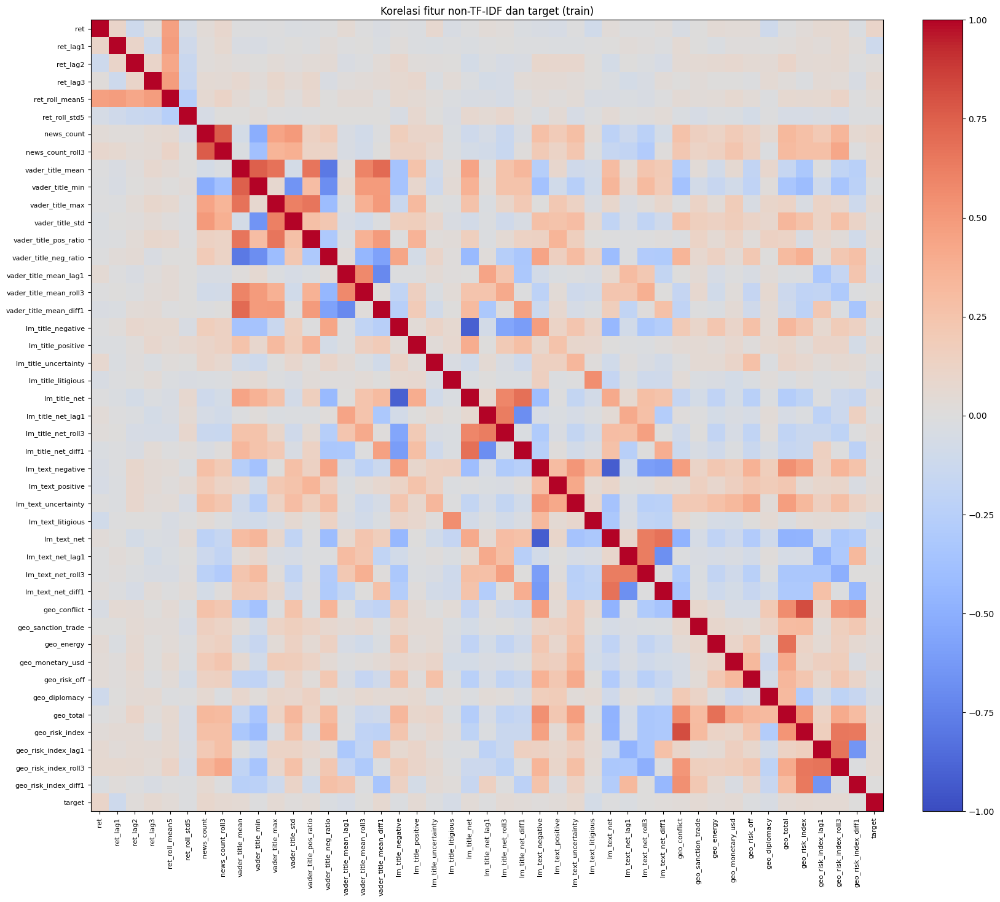

In [42]:
# ===== CORRELATION HEATMAP: semua fitur non-TF-IDF + target (train saja) =====
import matplotlib.pyplot as plt

def corr_heatmap(df, cols, title, annotate=False):
    cm = df[cols].corr().fillna(0.0)                 # fitur konstan -> korelasi 0
    size = max(6, 0.32 * len(cols) + 3)
    fig, ax = plt.subplots(figsize=(size, size * 0.85))
    im = ax.imshow(cm.values, cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(cols, rotation=90, fontsize=8)
    ax.set_yticks(range(len(cols)))
    ax.set_yticklabels(cols, fontsize=8)
    if annotate:
        for i in range(len(cols)):
            for j in range(len(cols)):
                ax.text(j, i, f'{cm.values[i, j]:.2f}', ha='center', va='center', fontsize=7)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

# TF-IDF tidak ikut karena ribuan kolom tidak terbaca di heatmap (dibahas di ranking di bawah)
dense_feats = [c for g, cols in GROUPS.items() if g != 'TF-IDF' for c in cols]
corr_heatmap(final_train, dense_feats + ['target'], 'Korelasi fitur non-TF-IDF dan target (train)')

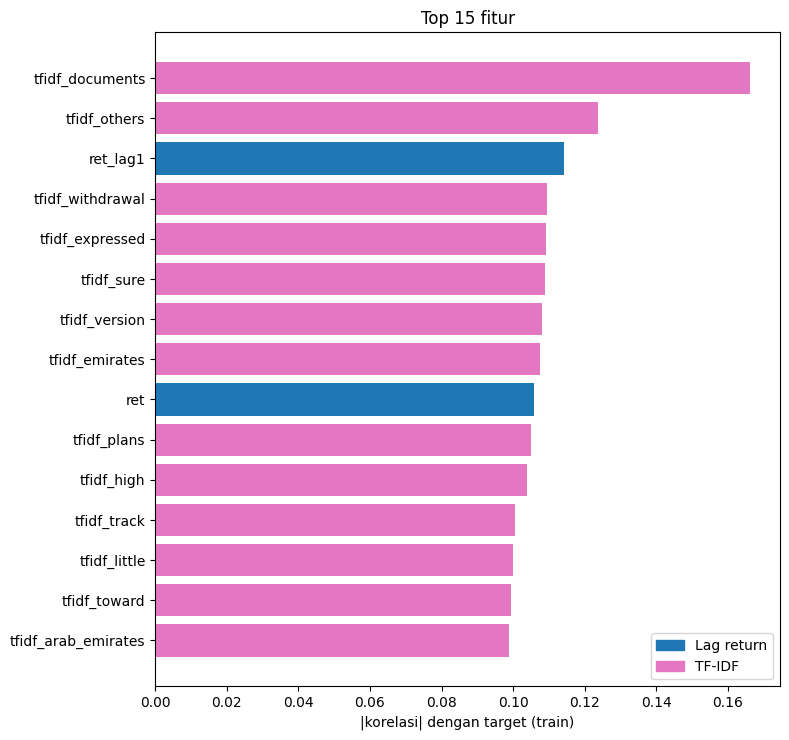

              fitur       grup  korelasi
    tfidf_documents     TF-IDF -0.166244
       tfidf_others     TF-IDF  0.123647
           ret_lag1 Lag return -0.114153
   tfidf_withdrawal     TF-IDF -0.109396
    tfidf_expressed     TF-IDF -0.109094
         tfidf_sure     TF-IDF  0.108937
      tfidf_version     TF-IDF  0.108052
     tfidf_emirates     TF-IDF -0.107640
                ret Lag return  0.105882
        tfidf_plans     TF-IDF -0.104901
         tfidf_high     TF-IDF  0.103802
        tfidf_track     TF-IDF  0.100637
       tfidf_little     TF-IDF  0.099993
       tfidf_toward     TF-IDF  0.099447
tfidf_arab_emirates     TF-IDF -0.098773

Ringkasan per grup (diurutkan dari rata-rata |korelasi|):
               jumlah_fitur  rata2_abs_corr  maks_abs_corr           fitur_terbaik
grup                                                                              
Jumlah berita             2          0.0734         0.0899              news_count
Lag return                6         

In [43]:
# ===== FEATURE SELECTION: ranking fitur (dihitung di TRAIN saja) =====
TOP_K = 15

all_feats = [c for cols in GROUPS.values() for c in cols]
feat2group = {c: g for g, cols in GROUPS.items() for c in cols}

# |korelasi Pearson| tiap fitur dengan target, hanya dari train (val/test tidak dipakai).
# Korelasi tidak terpengaruh skala, jadi adil membandingkan lag, sentimen, dan TF-IDF.
corr = final_train[all_feats].corrwith(final_train['target']).fillna(0.0)   # fitur konstan -> 0
ranking = corr.abs().sort_values(ascending=False)
top_feats = ranking.head(min(TOP_K, len(all_feats))).index.tolist()

cmap = plt.get_cmap('tab10')
palette = {g: cmap(i) for i, g in enumerate(GROUPS)}

plot_df = pd.DataFrame({
    'fitur': top_feats,
    'abs_corr': ranking.loc[top_feats].values,
    'korelasi': corr.loc[top_feats].values,
    'grup': [feat2group[f] for f in top_feats],
}).iloc[::-1]   # dibalik supaya yang terbesar ada di atas

fig, ax = plt.subplots(figsize=(8, 0.4 * len(top_feats) + 1.5))
ax.barh(plot_df['fitur'], plot_df['abs_corr'], color=plot_df['grup'].map(palette))
ax.set_xlabel('|korelasi| dengan target (train)')
ax.set_title(f'Top {len(top_feats)} fitur')
used = [g for g in GROUPS if g in set(plot_df['grup'])]
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=palette[g]) for g in used], labels=used, loc='lower right')
plt.tight_layout()
plt.show()

print(plot_df.iloc[::-1][['fitur', 'grup', 'korelasi']].to_string(index=False))

# Ringkasan per grup: grup mana yang paling berpengaruh
tmp = pd.DataFrame({'grup': [feat2group[f] for f in all_feats], 'abs_corr': corr.abs().values}, index=all_feats)
summary = tmp.groupby('grup')['abs_corr'].agg(jumlah_fitur='size', rata2_abs_corr='mean', maks_abs_corr='max')
summary['fitur_terbaik'] = tmp.groupby('grup')['abs_corr'].idxmax()
print('\nRingkasan per grup (diurutkan dari rata-rata |korelasi|):')
print(summary.sort_values('rata2_abs_corr', ascending=False).round(4).to_string())
print('\nCatatan: grup TF-IDF punya ribuan fitur, jadi nilai maksimumnya bisa tinggi hanya karena kebetulan.')

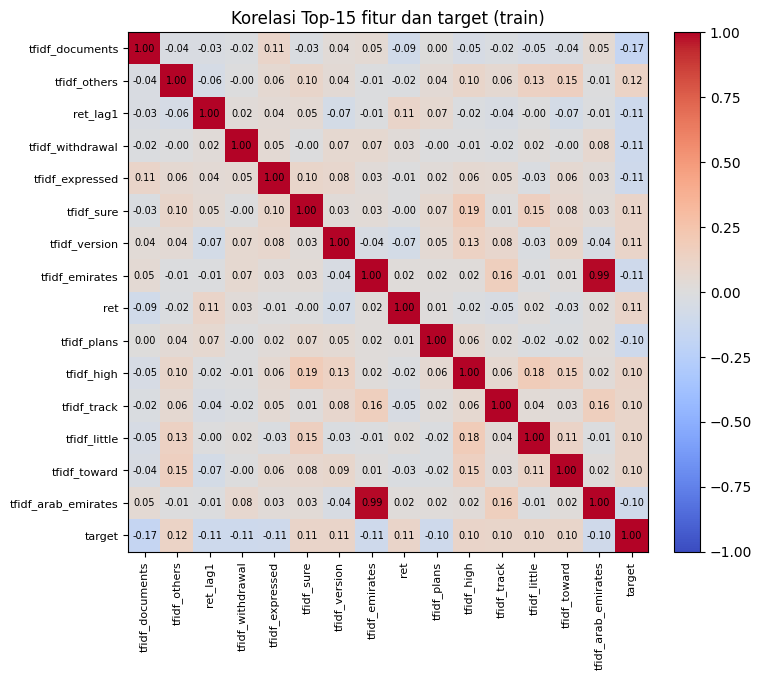

In [44]:
# ===== CORRELATION HEATMAP: fitur terpilih (top-K) dan target (train saja) =====
corr_heatmap(final_train, top_feats + ['target'], f'Korelasi Top-{len(top_feats)} fitur dan target (train)', annotate=True)

In [45]:
# ===== TRAIN ULANG dengan fitur terpilih (top-K) =====
# (memakai evaluate, y_tr/y_va/y_te, alphas, dan results dari cell regresi di atas)
K = len(top_feats)
scaler = StandardScaler().fit(final_train[top_feats])          # fit HANYA di train
X_tr = scaler.transform(final_train[top_feats])
X_va = scaler.transform(final_val[top_feats])
X_te = scaler.transform(final_test[top_feats])

rows_sel = []

# 1. Linear Regression biasa
ols = LinearRegression().fit(X_tr, y_tr)
rows_sel.append({'Model': f'LinReg | Top-{K}', 'Set': 'Val',  **evaluate(y_va, ols.predict(X_va))})
rows_sel.append({'Model': f'LinReg | Top-{K}', 'Set': 'Test', **evaluate(y_te, ols.predict(X_te))})

# 2. Ridge, alpha dipilih dari RMSE di validation
val_rmse = {a: evaluate(y_va, Ridge(alpha=a).fit(X_tr, y_tr).predict(X_va))['RMSE'] for a in alphas}
best_a = min(val_rmse, key=val_rmse.get)
ridge = Ridge(alpha=best_a).fit(X_tr, y_tr)
rows_sel.append({'Model': f'Ridge(a={best_a}) | Top-{K}', 'Set': 'Val',  **evaluate(y_va, ridge.predict(X_va))})
rows_sel.append({'Model': f'Ridge(a={best_a}) | Top-{K}', 'Set': 'Test', **evaluate(y_te, ridge.predict(X_te))})

results_sel = pd.DataFrame(rows_sel)
results_sel['DirAcc'] = results_sel['DirAcc'].round(3)
results_sel[['RMSE', 'MAE']] = results_sel[['RMSE', 'MAE']].round(6)

# gabungkan dengan hasil sebelumnya untuk perbandingan
results_all = pd.concat([results, results_sel], ignore_index=True)

print("=== VALIDATION ===")
print(results_all[results_all['Set'] == 'Val'].drop(columns='Set').to_string(index=False))
print("\n=== TEST ===")
print(results_all[results_all['Set'] == 'Test'].drop(columns='Set').to_string(index=False))

=== VALIDATION ===
                                Model     RMSE      MAE  DirAcc
                    Naive: prediksi 0 0.003382 0.002470     NaN
                Naive: return kemarin 0.004611 0.003468   0.500
             LinReg | Lag return saja 0.003373 0.002499   0.517
      Ridge(a=1000) | Lag return saja 0.003365 0.002473   0.539
         LinReg | Lag + Jumlah berita 0.003351 0.002538   0.483
   Ridge(a=0.1) | Lag + Jumlah berita 0.003351 0.002538   0.483
                 LinReg | Lag + VADER 0.003454 0.002599   0.449
         Ridge(a=10000) | Lag + VADER 0.003380 0.002466   0.522
              LinReg | Lag + LM judul 0.003362 0.002491   0.528
        Ridge(a=100) | Lag + LM judul 0.003360 0.002482   0.534
                LinReg | Lag + LM isi 0.003411 0.002531   0.506
        Ridge(a=10000) | Lag + LM isi 0.003377 0.002467   0.517
            LinReg | Lag + Geopolitik 0.003360 0.002496   0.545
     Ridge(a=1000) | Lag + Geopolitik 0.003352 0.002464   0.483
        LinReg | Lag 

In [46]:
# 1. Berapa hari tanpa berita
no_news = merged_data['news_count'] == 0
print(f"Hari tanpa berita: {no_news.sum()} dari {len(merged_data)} ({no_news.mean():.1%})")

# 2. Artikel yang hilang karena tanggal alignment-nya tidak ada di data kurs (misal hari libur)
bi_dates = set(pd.to_datetime(bi_raw['Tanggal_dt']).dt.normalize())
lost = daily_news[~daily_news['aligned_trading_date'].isin(bi_dates)]
print(f"Tanggal berita tanpa pasangan kurs: {len(lost)} hari, {lost['news_count'].sum()} artikel")

# 3. Sebaran per tahun dan per hari dalam seminggu
print(merged_data.groupby(merged_data['Tanggal_dt'].dt.year)['news_count']
      .agg(hari='size', tanpa_berita=lambda s: (s == 0).sum(), rata2='mean').round(2))
print(merged_data.groupby(merged_data['Tanggal_dt'].dt.day_name())['news_count'].mean().round(2))

Hari tanpa berita: 135 dari 1202 (11.2%)
Tanggal berita tanpa pasangan kurs: 0 hari, 0 artikel
            hari  tanpa_berita  rata2
Tanggal_dt                           
2021          87            24   1.38
2022         246            25   3.44
2023         239            35   2.65
2024         238            25   3.46
2025         237            24   3.16
2026         155             2   7.48
Tanggal_dt
Friday       3.08
Monday       5.18
Thursday     3.08
Tuesday      3.08
Wednesday    3.61
Name: news_count, dtype: float64
